# Notebook 6 -- Quelle representation nourrit le mieux un modele supervise ?
### SSI, SINDy, retards temporels et CNN 1D comme entrees d'XGBoost

> ****Note de provenance.**** Les notebooks de recherche originaux seront présents dans le répertoire du projet, accompagnés des données et des fichiers nécessaires aux expériences. Le présent notebook fait uniquement office de **notebook d'analyse et de synthèse** : il ne remplace pas les notebooks originaux et ne constitue pas une nouvelle implémentation des expérimentations.
>
> Le code, les résultats et les sorties présentés dans ce notebook sont analysés à partir des travaux réalisés dans les notebooks originaux. Aucun résultat n'a été recalculé ni inventé : lorsqu'une information n'était pas déterminable à partir des notebooks ou des données disponibles, cela est signalé explicitement plutôt que comblé. Ce notebook n'est donc pas conçu pour être exécuté isolément de haut en bas ; il a pour objectif de **documenter, structurer, comparer et interpréter les résultats déjà obtenus**, ainsi que de mettre en évidence la progression scientifique entre les différentes approches étudiées.


## Avertissement sur le jeu de donnees utilise dans ce notebook et le suivant

Ce notebook et le notebook 7 utilisent `preprocessed_data1.csv` (15 686 lignes, 3 equipements
A/B/C, decoupage 60/20/20 *par equipement*) et non `preprocessed_data.csv` utilise par les
notebooks 1, 2, 4 et 5 (voir notebook 1 pour le detail de cette difference). Les resultats
chiffres de ce notebook ne sont donc pas obtenus exactement sur le meme perimetre de donnees que
ceux des notebooks precedents ; la comparaison au notebook 8 le rappellera explicitement partout
ou elle est faite.

## Objectif

Le notebook 5 a montre qu'un observateur fonde sur une dynamique explicite (SINDy) n'apporte pas
de gain, et que le pipeline complet reste moins bon qu'une regression lineaire statique. Ce
notebook change de logique : plutot que de chercher une equation interpretable, il laisse un
modele d'apprentissage supervise (XGBoost, gradient boosting sur arbres) apprendre directement une
relation, potentiellement non lineaire, entre les capteurs disponibles et la cible -- et cherche a
determiner **quelle representation d'entree** (etat SSI, sortie SINDy, retards temporels bruts,
motifs locaux extraits par un CNN 1D) lui est la plus utile.

## Motivation

SINDy cherche une dynamique parcimonieuse et interpretable ; la regression du notebook 2 cherche
une relation lineaire instantanee. XGBoost est conceptuellement different des deux : il cherche une
relation **non lineaire** entre des variables d'entree (quelles qu'elles soient) et la cible, sans
imposer de forme fonctionnelle explicite ni de contrainte d'interpretabilite directe. Le CNN 1D,
introduit dans certaines variantes comme extracteur de motifs locaux, est different des trois :
il apprend automatiquement une representation a partir de sequences brutes, sans feature
engineering explicite. Ce notebook teste six combinaisons de ces briques.

## Hypothese

Une representation enrichie (etat latent SSI, dynamique SINDy meme degeneree, retards temporels,
motifs locaux appris par un CNN) fournie a un modele non lineaire (XGBoost) permet une
reconstruction plus fidele qu'une relation lineaire statique ou qu'un pipeline physique explicite.

## Methodologie

SSI est ré-identifié sur `preprocessed_data1.csv` avec le même algorithme qu'au notebook 5, mais
en excluant explicitement le capteur cible des l'identification (`OBS_SSI_SENSORS`) :

TRAIN
equipment_id
A    6205
B    3163
C      42
Name: count, dtype: int64

VALIDATION
equipment_id
A    2068
B    1054
C      14
Name: count, dtype: int64

TEST
equipment_id
A    2069
B    1056
C      15
Name: count, dtype: int64


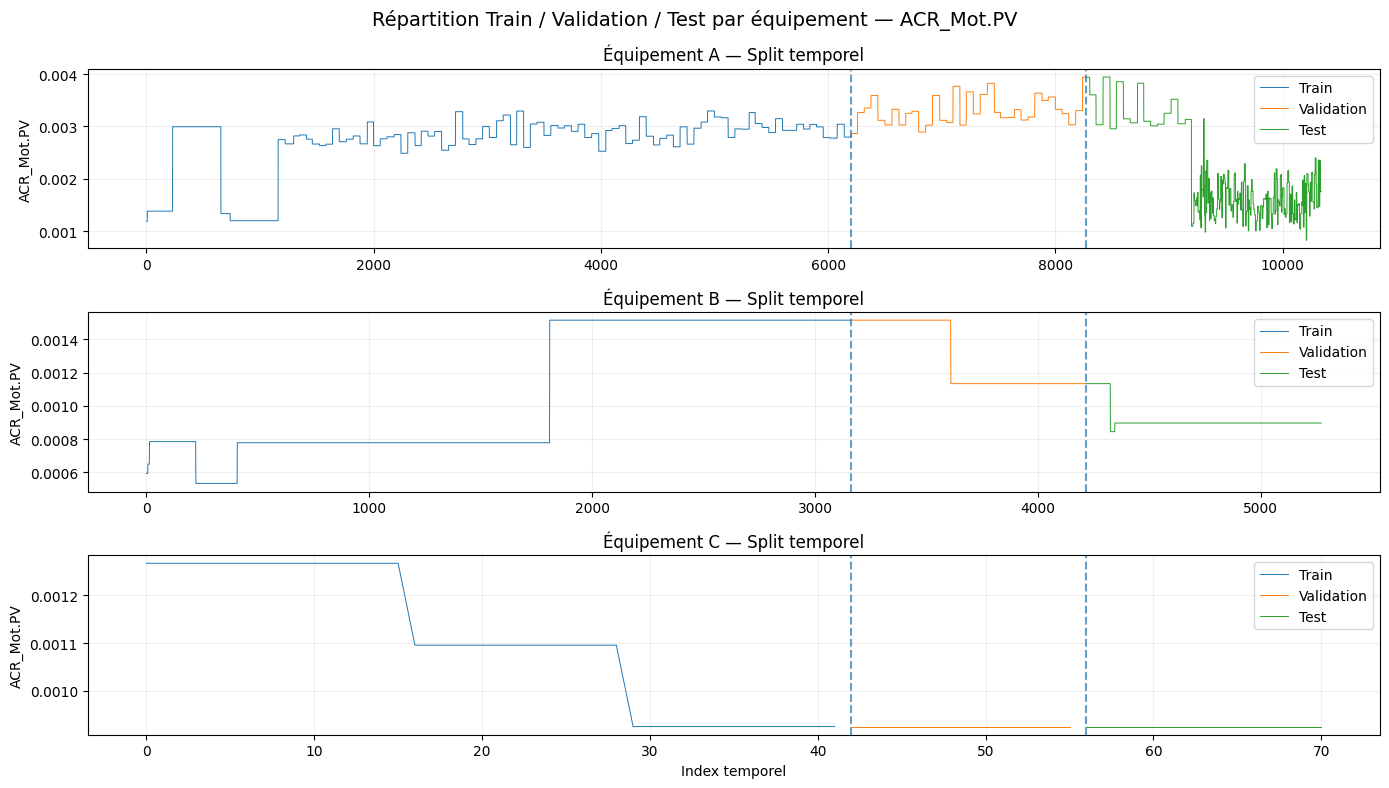

In [4]:
# ============================================================
# 1. Split temporel PAR ÉQUIPEMENT
# ============================================================

TRAIN_FRAC = 0.60
VAL_FRAC   = 0.20
TEST_FRAC  = 0.20

train_list = []
val_list   = []
test_list  = []

for equipment in df_raw["equipment_id"].unique():

    df_eq = (
        df_raw[df_raw["equipment_id"] == equipment]
        .sort_index()
        .reset_index(drop=True)
    )

    N = len(df_eq)

    n_train = int(N * TRAIN_FRAC)
    n_val   = int(N * VAL_FRAC)

    # Train
    train_eq = df_eq.iloc[:n_train].copy()

    # Validation
    val_eq = df_eq.iloc[n_train:n_train+n_val].copy()

    # Test
    test_eq = df_eq.iloc[n_train+n_val:].copy()

    train_list.append(train_eq)
    val_list.append(val_eq)
    test_list.append(test_eq)


# ============================================================
# 2. Reconstruction des DataFrames
# ============================================================

df_train = pd.concat(train_list, ignore_index=True)
df_val   = pd.concat(val_list, ignore_index=True)
df_test  = pd.concat(test_list, ignore_index=True)


# ============================================================
# 3. Vérification
# ============================================================

print("TRAIN")
print(df_train["equipment_id"].value_counts())

print("\nVALIDATION")
print(df_val["equipment_id"].value_counts())

print("\nTEST")
print(df_test["equipment_id"].value_counts())

import matplotlib.pyplot as plt

# ============================================================
# Visualisation du split temporel par équipement
# ============================================================

equipments = sorted(df_raw["equipment_id"].unique())

fig, axes = plt.subplots(
    len(equipments), 1,
    figsize=(14, 8),
    sharex=False
)

if len(equipments) == 1:
    axes = [axes]

for ax, equipment in zip(axes, equipments):

    # Données de cet équipement
    train_eq = df_train[
        df_train["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    val_eq = df_val[
        df_val["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    test_eq = df_test[
        df_test["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    # Indices temporels
    train_idx = range(len(train_eq))

    val_idx = range(
        len(train_eq),
        len(train_eq) + len(val_eq)
    )

    test_idx = range(
        len(train_eq) + len(val_eq),
        len(train_eq) + len(val_eq) + len(test_eq)
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------
    ax.plot(
        train_idx,
        train_eq,
        label="Train",
        lw=0.7
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    ax.plot(
        val_idx,
        val_eq,
        label="Validation",
        lw=0.7
    )

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------
    ax.plot(
        test_idx,
        test_eq,
        label="Test",
        lw=0.7
    )

    # Séparations
    ax.axvline(
        len(train_eq),
        linestyle="--",
        alpha=0.7
    )

    ax.axvline(
        len(train_eq) + len(val_eq),
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(
        f"Équipement {equipment} — Split temporel"
    )

    ax.set_ylabel(TARGET_SENSOR)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")


axes[-1].set_xlabel("Index temporel")

fig.suptitle(
    f"Répartition Train / Validation / Test par équipement — {TARGET_SENSOR}",
    fontsize=14
)

plt.tight_layout()
plt.show()

SINDy est réappliqué sur ces nouveaux états SSI, avec la bibliothèque enrichie du notebook 4 --
et échoue de la même façon (0 terme actif, instabilité en simulation libre). Le code n'est pas
reproduit ici une seconde fois (voir notebook 4) ; ses sorties dégénérées (dérivées et prédictions
"one-step" proches de zéro ou instables) sont malgré tout utilisées comme features dans certaines
variantes ci-dessous, exactement comme dans le notebook source -- ce qui permet justement de
mesurer si XGBoost peut « absorber » une feature peu informative sans être pénalisé.

### Variante 1 -- SSI + SINDy + retards (lags) → XGBoost

SSI SANS LE CAPTEUR CIBLE
Capteur cible : ACR_Mot.PV
Capteurs disponibles : ['ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Dimensions des états SSI :
Train : (9396, 8)
Validation : (3122, 8)
Test : (3126, 8)

... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (30 lignes omises) ...

R²          = 0.857385
Corrélation = 0.973241

XGBoost + SSI + SINDy — Test
RMSE        = 0.000619
MAE         = 0.000459
R²          = 0.629278
Corrélation = 0.895190


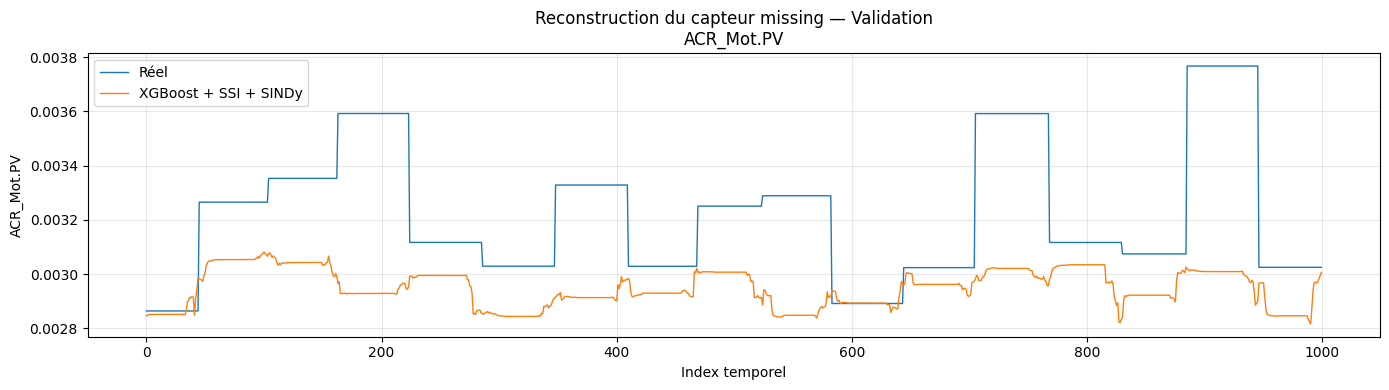

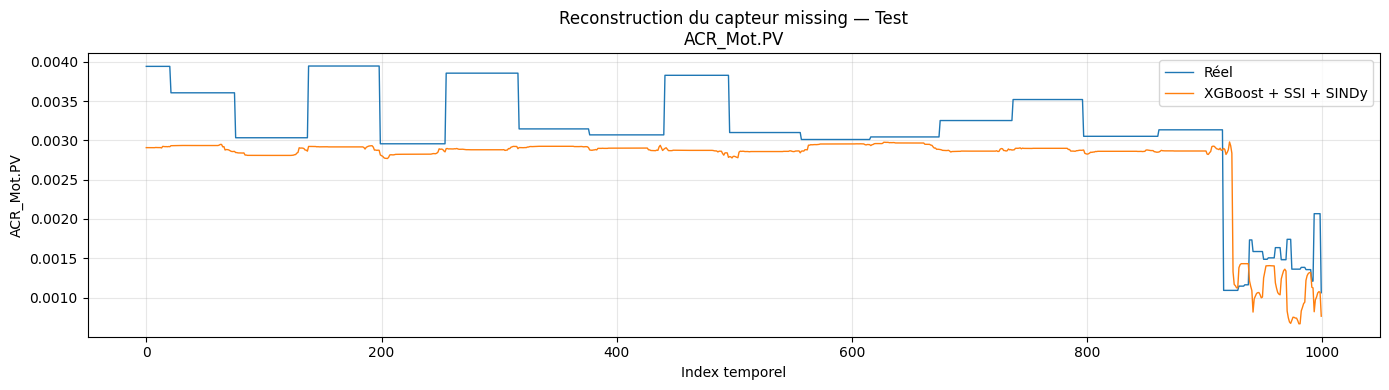

In [12]:
# ============================================================
# SSI → SINDy → XGBoost
# VERSION SANS CAPTEUR CIBLE DANS LES ENTRÉES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ============================================================
# 1. ÉTATS SSI ESTIMÉS UNIQUEMENT AVEC LES CAPTEURS DISPONIBLES
# ============================================================

Y_train_obs = train_s[
    OBS_SSI_SENSORS
].values

Y_val_obs = val_s[
    OBS_SSI_SENSORS
].values

Y_test_obs = test_s[
    OBS_SSI_SENSORS
].values


# ------------------------------------------------------------
# Identification SSI sur TRAIN uniquement
# ------------------------------------------------------------

A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER
)


print("=" * 60)
print("SSI SANS LE CAPTEUR CIBLE")
print("=" * 60)

print("Capteur cible :", TARGET_SENSOR)

print(
    "Capteurs disponibles :",
    OBS_SSI_SENSORS
)


# ============================================================
# 2. ESTIMATION DES ÉTATS SSI
# ============================================================

X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)


print("\nDimensions des états SSI :")

print(
    "Train :",
    X_train_hat_obs.shape
)

print(
    "Validation :",
    X_val_hat_obs.shape
)

print(
    "Test :",
    X_test_hat_obs.shape
)


# ============================================================
# 3. SINDy
# ============================================================

# ------------------------------------------------------------
# IMPORTANT :
# SINDy est entraîné UNIQUEMENT sur les états SSI
# construits avec les capteurs disponibles.
# ------------------------------------------------------------

sindy_model.fit(
    X_train_hat_obs,
    t=np.arange(
        len(X_train_hat_obs)
    ) * DT_APPROX
)


# ============================================================
# 4. DYNAMIQUE SINDy
# ============================================================

Xdot_train_sindy = sindy_model.predict(
    X_train_hat_sindy
)

Xdot_val_sindy = sindy_model.predict(
    X_val_hat_sindy
)
X_test_hat_sindy = SINDY_SCALER.transform(
    X_test_hat_obs
)

Xdot_test_sindy = sindy_model.predict(
    X_test_hat_sindy
)


# ============================================================
# 5. PRÉDICTION ONE-STEP SINDy
# ============================================================

Xnext_train_sindy = (
    sindy_model.predict_one_step(
        X_train_hat_sindy,
        DT_APPROX
    )
)

Xnext_val_sindy = (
    sindy_model.predict_one_step(
        X_val_hat_sindy,
        DT_APPROX
    )
)

Xnext_test_sindy = (
    sindy_model.predict_one_step(
        X_test_hat_sindy,
        DT_APPROX
    )
)


# ============================================================
# 6. ALIGNEMENT DES DIMENSIONS
# ============================================================
#
# predict_one_step peut retourner N-1 points.
# On enlève le dernier état SSI pour que toutes les
# features aient la même longueur.
# ============================================================

n_train = min(
    len(X_train_hat_obs),
    len(Xdot_train_sindy),
    len(Xnext_train_sindy)
)

n_val = min(
    len(X_val_hat_obs),
    len(Xdot_val_sindy),
    len(Xnext_val_sindy)
)

n_test = min(
    len(X_test_hat_obs),
    len(Xdot_test_sindy),
    len(Xnext_test_sindy)
)


# ============================================================
# 7. FEATURES SSI + SINDy
# ============================================================

X_train_sindy_features = np.column_stack([
    X_train_hat_obs[:n_train],
    Xdot_train_sindy[:n_train],
    Xnext_train_sindy[:n_train]
])


X_val_sindy_features = np.column_stack([
    X_val_hat_obs[:n_val],
    Xdot_val_sindy[:n_val],
    Xnext_val_sindy[:n_val]
])


X_test_sindy_features = np.column_stack([
    X_test_hat_obs[:n_test],
    Xdot_test_sindy[:n_test],
    Xnext_test_sindy[:n_test]
])


print("\nDimensions des features SSI + SINDy :")

print(
    "Train :",
    X_train_sindy_features.shape
)

print(
    "Validation :",
    X_val_sindy_features.shape
)

print(
    "Test :",
    X_test_sindy_features.shape
)


# ============================================================
# 8. LAGS DES CAPTEURS DISPONIBLES
# ============================================================

N_LAGS = 10


def create_lag_features(
    df,
    sensor_columns,
    n_lags
):

    data = {}

    for sensor in sensor_columns:

        for lag in range(
            n_lags + 1
        ):

            data[
                f"{sensor}_lag{lag}"
            ] = df[
                sensor
            ].shift(lag)

    return pd.DataFrame(
        data,
        index=df.index
    )


X_train_lags = create_lag_features(
    train_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_val_lags = create_lag_features(
    val_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_test_lags = create_lag_features(
    test_s,
    OBS_SSI_SENSORS,
    N_LAGS
)


# ============================================================
# 9. ALIGNEMENT LAGS + SSI + SINDy
# ============================================================

X_train_hybrid = pd.concat(
    [
        X_train_lags.reset_index(drop=True),
        pd.DataFrame(
            X_train_sindy_features
        )
    ],
    axis=1
)


X_val_hybrid = pd.concat(
    [
        X_val_lags.reset_index(drop=True),
        pd.DataFrame(
            X_val_sindy_features
        )
    ],
    axis=1
)


X_test_hybrid = pd.concat(
    [
        X_test_lags.reset_index(drop=True),
        pd.DataFrame(
            X_test_sindy_features
        )
    ],
    axis=1
)


# ============================================================
# 10. ALIGNEMENT FINAL AVEC LES TARGETS
# ============================================================

y_train_full = train_s[
    TARGET_SENSOR
].reset_index(drop=True)


y_val_full = val_s[
    TARGET_SENSOR
].reset_index(drop=True)


y_test_full = test_s[
    TARGET_SENSOR
].reset_index(drop=True)


# ============================================================
# 11. MASQUES VALIDES
# ============================================================

train_mask = (
    X_train_hybrid.notna().all(axis=1)
    &
    y_train_full.notna()
)

val_mask = (
    X_val_hybrid.notna().all(axis=1)
    &
    y_val_full.notna()
)

test_mask = (
    X_test_hybrid.notna().all(axis=1)
    &
    y_test_full.notna()
)


X_train_hybrid = X_train_hybrid.loc[
    train_mask
].reset_index(drop=True)

X_val_hybrid = X_val_hybrid.loc[
    val_mask
].reset_index(drop=True)

X_test_hybrid = X_test_hybrid.loc[
    test_mask
].reset_index(drop=True)


y_train = y_train_full.loc[
    train_mask
].reset_index(drop=True)

y_val = y_val_full.loc[
    val_mask
].reset_index(drop=True)

y_test = y_test_full.loc[
    test_mask
].reset_index(drop=True)


# ============================================================
# 12. XGBOOST HYBRIDE
# ============================================================

XGB_PARAMS = {
    "n_estimators": 500,
    "max_depth": 6,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}


xgb_hybrid = XGBRegressor(
    **XGB_PARAMS
)


xgb_hybrid.fit(
    X_train_hybrid,
    y_train
)


# ============================================================
# 13. PRÉDICTIONS
# ============================================================

# ------------------------------------------------------------
# IMPORTANT :
# y_val et y_test restent les vraies valeurs standardisées.
# NE PAS les écraser avec les prédictions.
# ------------------------------------------------------------

y_val_pred_scaled = xgb_hybrid.predict(
    X_val_hybrid
)

y_test_pred_scaled = xgb_hybrid.predict(
    X_test_hybrid
)


# ============================================================
# 14. RETOUR À L'ÉCHELLE ORIGINALE DU TARGET UNIQUEMENT
# ============================================================

# ------------------------------------------------------------
# Le scaler a été entraîné sur les 10 capteurs.
# On récupère la position exacte de TARGET_SENSOR.
# ------------------------------------------------------------

TARGET_IDX = list(train_s.columns).index(TARGET_SENSOR)

print("=" * 60)
print("INVERSE TRANSFORM DU TARGET")
print("=" * 60)

print("Target :", TARGET_SENSOR)
print("Index du target dans le scaler :", TARGET_IDX)

print("Mean target :", scaler.mean_[TARGET_IDX])
print("Scale target :", scaler.scale_[TARGET_IDX])


# ------------------------------------------------------------
# Paramètres du StandardScaler correspondant au target
# ------------------------------------------------------------

TARGET_MEAN = scaler.mean_[TARGET_IDX]
TARGET_SCALE = scaler.scale_[TARGET_IDX]


# ------------------------------------------------------------
# Retour à l'échelle physique
# ------------------------------------------------------------

y_val_original = (
    y_val.values * TARGET_SCALE
    + TARGET_MEAN
)

y_val_pred_original = (
    y_val_pred_scaled * TARGET_SCALE
    + TARGET_MEAN
)


y_test_original = (
    y_test.values * TARGET_SCALE
    + TARGET_MEAN
)

y_test_pred_original = (
    y_test_pred_scaled * TARGET_SCALE
    + TARGET_MEAN
)


print("\nDimensions :")

print(
    "y_val_original :",
    y_val_original.shape
)

print(
    "y_val_pred_original :",
    y_val_pred_original.shape
)

print(
    "y_test_original :",
    y_test_original.shape
)

print(
    "y_test_pred_original :",
    y_test_pred_original.shape
)

# ============================================================
# 14. RETOUR À L'ÉCHELLE ORIGINALE
# ============================================================

# ------------------------------------------------------------
# y_val / y_test :
# vraies valeurs standardisées
#
# y_val_pred_scaled / y_test_pred_scaled :
# prédictions standardisées
#
# On inverse la transformation pour obtenir les valeurs
# dans l'unité physique originale du capteur.
# ------------------------------------------------------------



# ============================================================
# 15. ÉVALUATION
# ============================================================

def evaluate(
    y_true,
    y_pred,
    name
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    corr = np.corrcoef(
        y_true,
        y_pred
    )[0, 1]

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        f"RMSE        = {rmse:.6f}"
    )

    print(
        f"MAE         = {mae:.6f}"
    )

    print(
        f"R²          = {r2:.6f}"
    )

    print(
        f"Corrélation = {corr:.6f}"
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Correlation": corr
    }


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

results_val = evaluate(
    y_val_original,
    y_val_pred_original,
    "XGBoost + SSI + SINDy — Validation"
)


# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

results_test = evaluate(
    y_test_original,
    y_test_pred_original,
    "XGBoost + SSI + SINDy — Test"
)


# ============================================================
# 16. VISUALISATION VALIDATION
# ============================================================

n_plot = min(
    1000,
    len(y_val_original)
)

plt.figure(
    figsize=(14, 4)
)

plt.plot(
    y_val_original[:n_plot],
    label="Réel",
    lw=1
)

plt.plot(
    y_val_pred_original[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1
)

plt.title(
    f"Reconstruction du capteur missing — Validation\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. VISUALISATION TEST
# ============================================================

n_plot = min(
    1000,
    len(y_test_original)
)

plt.figure(
    figsize=(14, 4)
)

plt.plot(
    y_test_original[:n_plot],
    label="Réel",
    lw=1
)

plt.plot(
    y_test_pred_original[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1
)

plt.title(
    f"Reconstruction du capteur missing — Test\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Test : R² = 0,629, corrélation = 0,895** (RMSE unité originale = 0,000619).

### Variante 2 -- CNN 1D + SSI + retards → XGBoost

ALIGNEMENT SSI
Train        | observations =   9410 | états SSI =   9396 | décalage SSI = 14
Validation   | observations =   3136 | états SSI =   3122 | décalage SSI = 14
Test         | observations =   3140 | états SSI =   3126 | décalage SSI = 14

Décalage SSI retenu : 14


... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (31 lignes omises) ...

Epoch 13/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0132 - mae: 0.0802 - val_loss: 0.2981 - val_mae: 0.4526
Epoch 14/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0120 - mae: 0.0762 - val_loss: 0.2687 - val_mae: 0.4179
Epoch 15/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0112 - mae: 0.0731 - val_loss: 0.2122 - val_mae: 0.3607

DIMENSIONS FINALES XGBOOST
Train      : (9381, 157)
Validation : (3107, 157)
Test       : (3111, 157)

Métriques dans l'espace standardisé :


,split,RMSE,MAE,R2,Correlation
0,Train,0.069506,0.045076,0.995172,0.997662
1,Validation,0.448067,0.353150,0.827484,0.961730
2,Test,0.497007,0.342749,0.796321,0.928147



Capteur cible : ACR_Mot.PV
TARGET_MEAN  : 0.00214400
TARGET_SCALE : 0.00091395

Métriques dans l'unité originale :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000064,0.000041,0.995172,0.997662
1,Validation,0.000410,0.000323,0.827484,0.961730
2,Test,0.000454,0.000313,0.796321,0.928147


,time_index_in_test,y_true_scaled,y_pred_scaled,y_true_original,y_pred_original
0,29,1.965860,0.954382,0.003941,0.003016
1,30,1.965860,0.954382,0.003941,0.003016
2,31,1.597892,0.954382,0.003604,0.003016
3,32,1.597892,0.954382,0.003604,0.003016
4,33,1.597892,0.948553,0.003604,0.003011


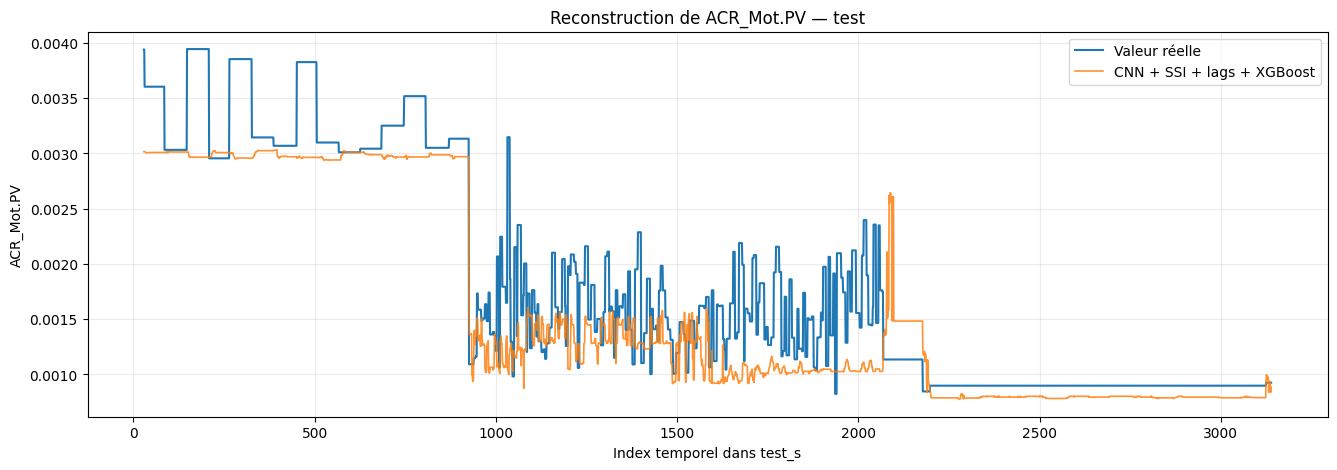

In [13]:
# ============================================================
# CNN 1D + SSI + Lags -> XGBoost
# Reconstruction de TARGET_SENSOR sans SINDy
#
# Prérequis :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# SSI_BLOCK_ROWS, SSI_ORDER
# ssi_cov(), ssi_estimate_states()
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# ============================================================
# 0. PARAMÈTRES
# ============================================================

SEED = 42

WINDOW = 30
N_LAGS = 10

CNN_EPOCHS = 100
CNN_BATCH_SIZE = 64
CNN_EMBEDDING_DIM = 32

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ============================================================
# 1. VÉRIFICATIONS
# ============================================================

required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
    "SSI_BLOCK_ROWS",
    "SSI_ORDER",
    "ssi_cov",
    "ssi_estimate_states",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables/fonctions manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être inclus dans OBS_SSI_SENSORS."
    )

if TARGET_SENSOR not in train_s.columns:
    raise ValueError(
        f"Le capteur cible {TARGET_SENSOR} est absent de train_s."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes."
    )


# ============================================================
# 2. DONNÉES OBSERVÉES ET CIBLE
# ============================================================

# Les entrées ne contiennent jamais le capteur cible.
Y_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

# La cible est disponible uniquement pour entraîner/évaluer.
y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)


# ============================================================
# 3. SSI : IDENTIFICATION UNIQUEMENT SUR TRAIN
# ============================================================

A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER,
)

X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_train_hat_obs = np.asarray(
    X_train_hat_obs,
    dtype=np.float32,
)

X_val_hat_obs = np.asarray(
    X_val_hat_obs,
    dtype=np.float32,
)

X_test_hat_obs = np.asarray(
    X_test_hat_obs,
    dtype=np.float32,
)


# ============================================================
# 4. DÉCALAGE SSI
#
# Exemple :
# 9410 observations et 9396 états SSI
# --> SSI_OFFSET = 14
#
# état SSI[k] correspond à l'instant brut t = k + 14
# ============================================================

def get_ssi_offset(states, observations, split_name):
    offset = len(observations) - len(states)

    if offset < 0:
        raise ValueError(
            f"SSI renvoie trop d'états sur {split_name}."
        )

    print(
        f"{split_name:<12} | "
        f"observations = {len(observations):>6} | "
        f"états SSI = {len(states):>6} | "
        f"décalage SSI = {offset}"
    )

    return offset


print("=" * 70)
print("ALIGNEMENT SSI")
print("=" * 70)

SSI_OFFSET_TRAIN = get_ssi_offset(
    X_train_hat_obs,
    Y_train_obs,
    "Train",
)

SSI_OFFSET_VAL = get_ssi_offset(
    X_val_hat_obs,
    Y_val_obs,
    "Validation",
)

SSI_OFFSET_TEST = get_ssi_offset(
    X_test_hat_obs,
    Y_test_obs,
    "Test",
)

if not (
    SSI_OFFSET_TRAIN
    == SSI_OFFSET_VAL
    == SSI_OFFSET_TEST
):
    raise ValueError(
        "Le décalage SSI doit être identique sur train, validation et test."
    )

SSI_OFFSET = SSI_OFFSET_TRAIN

print("\nDécalage SSI retenu :", SSI_OFFSET)


# ============================================================
# 5. CONSTRUCTION DES FEATURES ALIGNÉES
#
# Pour le même instant brut t :
#
# CNN  = observés[t-WINDOW+1 : t+1]
# Lags = observés[t], ..., observés[t-N_LAGS]
# SSI  = état SSI[t - SSI_OFFSET]
# y    = cible[t]
# ============================================================

def build_aligned_split(
    observed_sensors,
    ssi_states,
    target,
    window,
    n_lags,
    ssi_offset,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    ssi_states = np.asarray(
        ssi_states,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    n_raw = len(target)

    if len(observed_sensors) != n_raw:
        raise ValueError(
            "Les observations et la cible n'ont pas la même longueur."
        )

    if len(ssi_states) != n_raw - ssi_offset:
        raise ValueError(
            "Les dimensions SSI sont incompatibles avec SSI_OFFSET."
        )

    # Premier instant où CNN, lags et SSI sont tous disponibles.
    first_t = max(
        window - 1,
        n_lags,
        ssi_offset,
    )

    if n_raw <= first_t:
        raise ValueError(
            "Pas assez d'observations pour construire les features."
        )

    valid_t = np.arange(
        first_t,
        n_raw,
    )

    # CNN : (n_exemples, WINDOW, n_capteurs_observés)
    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    # Lags : x(t), x(t-1), ..., x(t-N_LAGS)
    X_lags = np.concatenate(
        [
            np.stack(
                [
                    observed_sensors[t - lag]
                    for t in valid_t
                ],
                axis=0,
            )
            for lag in range(n_lags + 1)
        ],
        axis=1,
    )

    # Variations : utiles pour les changements rapides.
    X_delta_1 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 1]
            for t in valid_t
        ],
        axis=0,
    )

    X_delta_3 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 3]
            for t in valid_t
        ],
        axis=0,
    )

    # Ajout des variations aux lags.
    X_lags = np.hstack([
        X_lags,
        X_delta_1,
        X_delta_3,
    ])

    # t brut -> index dans le tableau des états SSI.
    ssi_indices = valid_t - ssi_offset

    X_ssi = ssi_states[ssi_indices]

    # Cible au même instant t.
    y = target[valid_t]

    return (
        X_cnn,
        X_lags,
        X_ssi,
        y,
        valid_t,
    )


(
    X_cnn_train,
    X_lags_train,
    X_ssi_train,
    y_train,
    idx_train,
) = build_aligned_split(
    Y_train_obs,
    X_train_hat_obs,
    y_train_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_val,
    X_lags_val,
    X_ssi_val,
    y_val,
    idx_val,
) = build_aligned_split(
    Y_val_obs,
    X_val_hat_obs,
    y_val_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_test,
    X_lags_test,
    X_ssi_test,
    y_test,
    idx_test,
) = build_aligned_split(
    Y_test_obs,
    X_test_hat_obs,
    y_test_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

print("\n" + "=" * 70)
print("DIMENSIONS APRÈS ALIGNEMENT")
print("=" * 70)
print("CNN train  :", X_cnn_train.shape)
print("Lags train :", X_lags_train.shape)
print("SSI train  :", X_ssi_train.shape)
print("y train    :", y_train.shape)


# ============================================================
# 6. CNN 1D
#
# Flatten préserve les positions temporelles ; GlobalAveragePooling
# lissait trop fortement les variations dans ton cas.
# ============================================================

n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(
        WINDOW,
        n_observed_sensors,
    ),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

x = tf.keras.layers.BatchNormalization()(x)

# Préserve la localisation temporelle des motifs.
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
)(x)

x = tf.keras.layers.Dense(
    CNN_EMBEDDING_DIM,
    activation="relu",
    name="cnn_embedding",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="cnn_target_prediction",
)(x)

cnn_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="cnn_1d_ssi_lags",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    )
]

history_cnn = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)


# ============================================================
# 7. EMBEDDINGS CNN
# ============================================================

cnn_embedding_model = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "cnn_embedding"
    ).output,
)

X_cnn_emb_train = cnn_embedding_model.predict(
    X_cnn_train,
    verbose=0,
)

X_cnn_emb_val = cnn_embedding_model.predict(
    X_cnn_val,
    verbose=0,
)

X_cnn_emb_test = cnn_embedding_model.predict(
    X_cnn_test,
    verbose=0,
)


# ============================================================
# 8. FUSION : CNN + SSI + LAGS
# ============================================================

X_train_final = np.hstack([
    X_cnn_emb_train,
    X_ssi_train,
    X_lags_train,
]).astype(np.float32)

X_val_final = np.hstack([
    X_cnn_emb_val,
    X_ssi_val,
    X_lags_val,
]).astype(np.float32)

X_test_final = np.hstack([
    X_cnn_emb_test,
    X_ssi_test,
    X_lags_test,
]).astype(np.float32)

print("\n" + "=" * 70)
print("DIMENSIONS FINALES XGBOOST")
print("=" * 70)
print("Train      :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)


# ============================================================
# 9. XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_alpha=0.01,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train_final,
    y_train,
    eval_set=[
        (
            X_val_final,
            y_val,
        )
    ],
    verbose=False,
)

# Les y restent les vraies valeurs ; on ne les écrase pas.
y_train_pred = xgb_model.predict(X_train_final)
y_val_pred = xgb_model.predict(X_val_final)
y_test_pred = xgb_model.predict(X_test_final)


# ============================================================
# 10. MÉTRIQUES
# ============================================================

def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": np.corrcoef(
            y_true,
            y_pred,
        )[0, 1],
    }


metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques dans l'espace standardisé :")
display(metrics_scaled)


# ============================================================
# 11. RETOUR À L'UNITÉ ORIGINALE
# ============================================================

TARGET_IDX = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[TARGET_IDX]
)

TARGET_SCALE = float(
    scaler.scale_[TARGET_IDX]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )


y_train_original = inverse_target_scale(y_train)
y_val_original = inverse_target_scale(y_val)
y_test_original = inverse_target_scale(y_test)

y_train_pred_original = inverse_target_scale(y_train_pred)
y_val_pred_original = inverse_target_scale(y_val_pred)
y_test_pred_original = inverse_target_scale(y_test_pred)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print(f"\nCapteur cible : {TARGET_SENSOR}")
print(f"TARGET_MEAN  : {TARGET_MEAN:.8f}")
print(f"TARGET_SCALE : {TARGET_SCALE:.8f}")

print("\nMétriques dans l'unité originale :")
display(metrics_original)


# ============================================================
# 12. VISUALISATION TEST
# ============================================================

results_test = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_scaled": y_test,
    "y_pred_scaled": y_test_pred,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

display(results_test.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_pred_original"],
    label="CNN + SSI + lags + XGBoost",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Test : R² = 0,796, corrélation = 0,928** (RMSE unité originale = 0,000454). Train R² = 0,995 -- écart Train/Test qui reste modéré.

### Variante 3 -- CNN 1D + retards → XGBoost (sans SSI)

DIMENSIONS APRÈS ALIGNEMENT
CNN train      : (9381, 30, 9)
Features train : (9381, 117)
Cible train    : (9381,)
CNN validation : (3107, 30, 9)
CNN test       : (3111, 30, 9)
Epoch 1/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.1400 - mae: 0.2356 - val_loss: 0.8236 - val_mae: 0.8304

... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (22 lignes omises) ...

Epoch 13/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0132 - mae: 0.0802 - val_loss: 0.2981 - val_mae: 0.4526
Epoch 14/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0120 - mae: 0.0762 - val_loss: 0.2687 - val_mae: 0.4179
Epoch 15/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0112 - mae: 0.0731 - val_loss: 0.2122 - val_mae: 0.3607

DIMENSIONS FINALES XGBOOST
Train      : (9381, 149)
Validation : (3107, 149)
Test       : (3111, 149)

Métriques dans l'espace standardisé :


,split,RMSE,MAE,R2,Correlation
0,Train,0.072501,0.046781,0.994747,0.997443
1,Validation,0.471557,0.380593,0.808922,0.961305
2,Test,0.489074,0.341083,0.802771,0.927517



Capteur cible : ACR_Mot.PV
TARGET_MEAN  : 0.00214400
TARGET_SCALE : 0.00091395

Métriques dans l'unité originale :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000066,0.000043,0.994747,0.997443
1,Validation,0.000431,0.000348,0.808922,0.961305
2,Test,0.000447,0.000312,0.802771,0.927517


,time_index_in_test,y_true_scaled,y_pred_scaled,y_true_original,y_pred_original
0,29,1.965860,0.925584,0.003941,0.002990
1,30,1.965860,0.925584,0.003941,0.002990
2,31,1.597892,0.925584,0.003604,0.002990
3,32,1.597892,0.925584,0.003604,0.002990
4,33,1.597892,0.916394,0.003604,0.002982


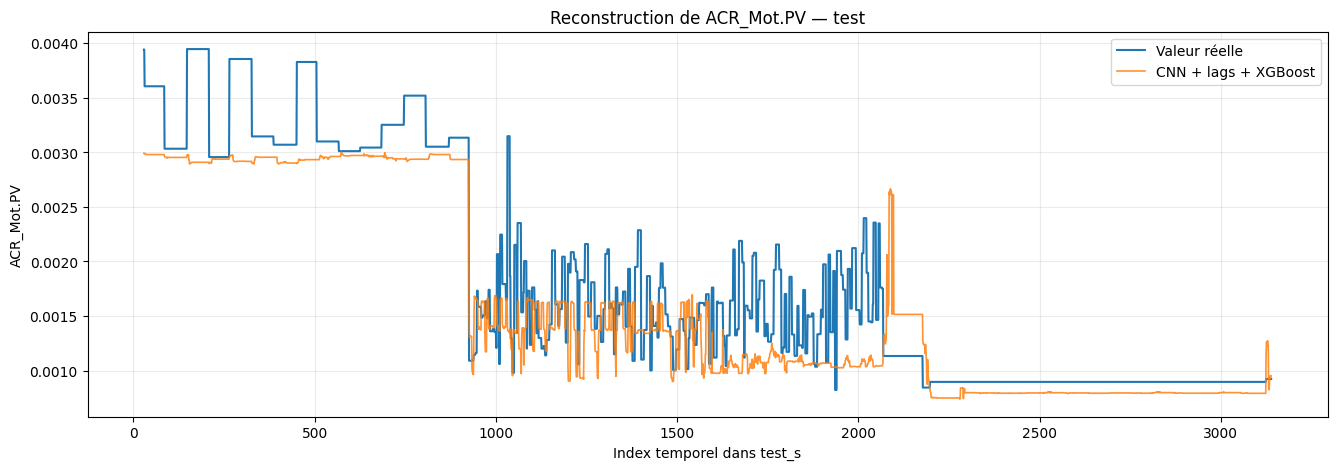

In [14]:
# ============================================================
# CNN 1D + Lags -> XGBoost
# Reconstruction de TARGET_SENSOR
# Sans SSI et sans SINDy
#
# Prérequis :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# ============================================================
# 0. PARAMÈTRES
# ============================================================

SEED = 42

WINDOW = 30
N_LAGS = 10

CNN_EPOCHS = 100
CNN_BATCH_SIZE = 64
CNN_EMBEDDING_DIM = 32

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ============================================================
# 1. VÉRIFICATIONS
# ============================================================

required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être inclus dans OBS_SSI_SENSORS."
    )

if TARGET_SENSOR not in train_s.columns:
    raise ValueError(
        f"Le capteur cible {TARGET_SENSOR} est absent de train_s."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes."
    )


# ============================================================
# 2. CAPTEURS OBSERVÉS ET CIBLE
# ============================================================

# Entrées : uniquement les capteurs observés.
X_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

# Cible : utilisée uniquement pour l'entraînement et l'évaluation.
y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)


# ============================================================
# 3. FEATURES TEMPORELLES ALIGNÉES
#
# À chaque instant t :
#
# CNN  : X[t-WINDOW+1 : t+1]
# Lags : X[t], X[t-1], ..., X[t-N_LAGS]
# Delta: X[t]-X[t-1] et X[t]-X[t-3]
# y    : TARGET_SENSOR[t]
# ============================================================

def build_aligned_split(
    observed_sensors,
    target,
    window,
    n_lags,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    if len(observed_sensors) != len(target):
        raise ValueError(
            "Les capteurs observés et la cible doivent avoir la même longueur."
        )

    n_samples = len(target)

    first_t = max(
        window - 1,
        n_lags,
        3,  # nécessaire à delta_3
    )

    if n_samples <= first_t:
        raise ValueError(
            f"Pas assez d'observations ({n_samples}) "
            f"pour WINDOW={window} et N_LAGS={n_lags}."
        )

    valid_t = np.arange(
        first_t,
        n_samples,
    )

    # CNN : shape (n_exemples, WINDOW, n_capteurs)
    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    # Lags : [X(t), X(t-1), ..., X(t-N_LAGS)]
    X_lags = np.concatenate(
        [
            np.stack(
                [
                    observed_sensors[t - lag]
                    for t in valid_t
                ],
                axis=0,
            )
            for lag in range(n_lags + 1)
        ],
        axis=1,
    )

    # Variations courtes : importantes dans les régimes transitoires.
    X_delta_1 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 1]
            for t in valid_t
        ],
        axis=0,
    )

    X_delta_3 = np.stack(
        [
            observed_sensors[t]
            - observed_sensors[t - 3]
            for t in valid_t
        ],
        axis=0,
    )

    X_tabular = np.hstack([
        X_lags,
        X_delta_1,
        X_delta_3,
    ])

    y = target[valid_t]

    return (
        X_cnn,
        X_tabular,
        y,
        valid_t,
    )


(
    X_cnn_train,
    X_tabular_train,
    y_train,
    idx_train,
) = build_aligned_split(
    X_train_obs,
    y_train_full,
    WINDOW,
    N_LAGS,
)

(
    X_cnn_val,
    X_tabular_val,
    y_val,
    idx_val,
) = build_aligned_split(
    X_val_obs,
    y_val_full,
    WINDOW,
    N_LAGS,
)

(
    X_cnn_test,
    X_tabular_test,
    y_test,
    idx_test,
) = build_aligned_split(
    X_test_obs,
    y_test_full,
    WINDOW,
    N_LAGS,
)

print("=" * 70)
print("DIMENSIONS APRÈS ALIGNEMENT")
print("=" * 70)
print("CNN train      :", X_cnn_train.shape)
print("Features train :", X_tabular_train.shape)
print("Cible train    :", y_train.shape)
print("CNN validation :", X_cnn_val.shape)
print("CNN test       :", X_cnn_test.shape)


# ============================================================
# 4. CNN 1D
#
# Flatten est utilisé pour garder les positions dans la fenêtre
# temporelle ; le pooling moyen lissait trop les variations.
# ============================================================

n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(
        WINDOW,
        n_observed_sensors,
    ),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
)(x)

x = tf.keras.layers.Dense(
    CNN_EMBEDDING_DIM,
    activation="relu",
    name="cnn_embedding",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="cnn_target_prediction",
)(x)

cnn_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="cnn_1d_lags",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    )
]

history_cnn = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)


# ============================================================
# 5. EXTRACTION DES EMBEDDINGS CNN
# ============================================================

cnn_embedding_model = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "cnn_embedding"
    ).output,
    name="cnn_embedding_extractor",
)

X_cnn_emb_train = cnn_embedding_model.predict(
    X_cnn_train,
    verbose=0,
)

X_cnn_emb_val = cnn_embedding_model.predict(
    X_cnn_val,
    verbose=0,
)

X_cnn_emb_test = cnn_embedding_model.predict(
    X_cnn_test,
    verbose=0,
)


# ============================================================
# 6. FUSION CNN + LAGS + VARIATIONS
# ============================================================

X_train_final = np.hstack([
    X_cnn_emb_train,
    X_tabular_train,
]).astype(np.float32)

X_val_final = np.hstack([
    X_cnn_emb_val,
    X_tabular_val,
]).astype(np.float32)

X_test_final = np.hstack([
    X_cnn_emb_test,
    X_tabular_test,
]).astype(np.float32)

print("\n" + "=" * 70)
print("DIMENSIONS FINALES XGBOOST")
print("=" * 70)
print("Train      :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)


# ============================================================
# 7. XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_alpha=0.01,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train_final,
    y_train,
    eval_set=[
        (
            X_val_final,
            y_val,
        )
    ],
    verbose=False,
)

# Ne jamais écraser y_test avec une prédiction.
y_train_pred = xgb_model.predict(X_train_final)
y_val_pred = xgb_model.predict(X_val_final)
y_test_pred = xgb_model.predict(X_test_final)


# ============================================================
# 8. MÉTRIQUES
# ============================================================

def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": np.corrcoef(
            y_true,
            y_pred,
        )[0, 1],
    }


metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques dans l'espace standardisé :")
display(metrics_scaled)


# ============================================================
# 9. RETOUR À L'ÉCHELLE ORIGINALE DU CAPTEUR CIBLE
# ============================================================

TARGET_IDX = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[TARGET_IDX]
)

TARGET_SCALE = float(
    scaler.scale_[TARGET_IDX]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )


y_train_original = inverse_target_scale(y_train)
y_val_original = inverse_target_scale(y_val)
y_test_original = inverse_target_scale(y_test)

y_train_pred_original = inverse_target_scale(y_train_pred)
y_val_pred_original = inverse_target_scale(y_val_pred)
y_test_pred_original = inverse_target_scale(y_test_pred)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print(f"\nCapteur cible : {TARGET_SENSOR}")
print(f"TARGET_MEAN  : {TARGET_MEAN:.8f}")
print(f"TARGET_SCALE : {TARGET_SCALE:.8f}")

print("\nMétriques dans l'unité originale :")
display(metrics_original)


# ============================================================
# 10. RÉSULTATS ET VISUALISATION TEST
# ============================================================

results_test = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_scaled": y_test,
    "y_pred_scaled": y_test_pred,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

display(results_test.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_pred_original"],
    label="CNN + lags + XGBoost",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Test : R² = 0,803, corrélation = 0,928** (RMSE unité originale = 0,000447) -- essentiellement identique à la variante 2 malgré l'absence de SSI.

### Variante 4 -- CNN 1D seul (témoin, sans XGBoost)

DIMENSIONS
Train      : (9381, 30, 9) (9381,)
Validation : (3107, 30, 9) (3107,)
Test       : (3111, 30, 9) (3111,)


Model: "cnn_1d_direct_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ observed_sensor_window          │ (None, 30, 9)          │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 30, 32)         │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 30, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 30, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ target_prediction (Dense)       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,505 (52.75 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0981 - mae: 0.2012 - val_loss: 0.8052 - val_mae: 0.8050 - learning_rate: 0.0010
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0408 - mae: 0.1405 - val_loss: 0.2876 - val_mae: 0.4449 - learning_rate: 0.0010
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0337 - mae: 0.1273 - val_loss: 0.1408 - val_mae: 0.2663 - learning_rate: 0.0010
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0307 - mae: 0.1210 - val_loss: 0.1601 - val_mae: 0.2947 - learning_rate: 0.0010
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0274 - mae: 0.1124 - val_loss: 0.1621 - val_mae: 0.2977 - learning_rate: 0.0010

... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (7 lignes omises) ...

146/147 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0229 - mae: 0.1028
Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
147/147 ━━━━━━━━━━━━━━━━━━━━ 1

,split,RMSE,MAE,R2,Correlation
0,Train,0.181641,0.123996,0.967026,0.983513
1,Validation,0.375257,0.266322,0.878995,0.965457
2,Test,0.775162,0.620577,0.504543,0.729576



Métriques — unité originale :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000166,0.000113,0.967026,0.983513
1,Validation,0.000343,0.000243,0.878995,0.965457
2,Test,0.000708,0.000567,0.504543,0.729576


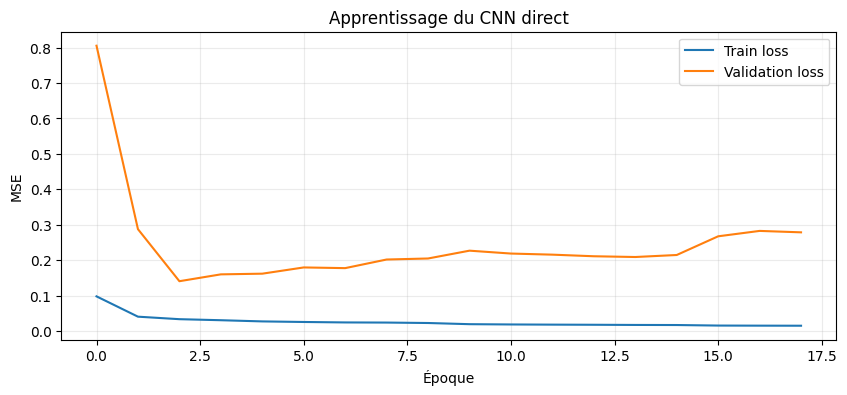

,time_index_in_test,y_true_original,y_pred_original
0,29,0.003941,0.003169
1,30,0.003941,0.003169
2,31,0.003604,0.003169
3,32,0.003604,0.003170
4,33,0.003604,0.003170


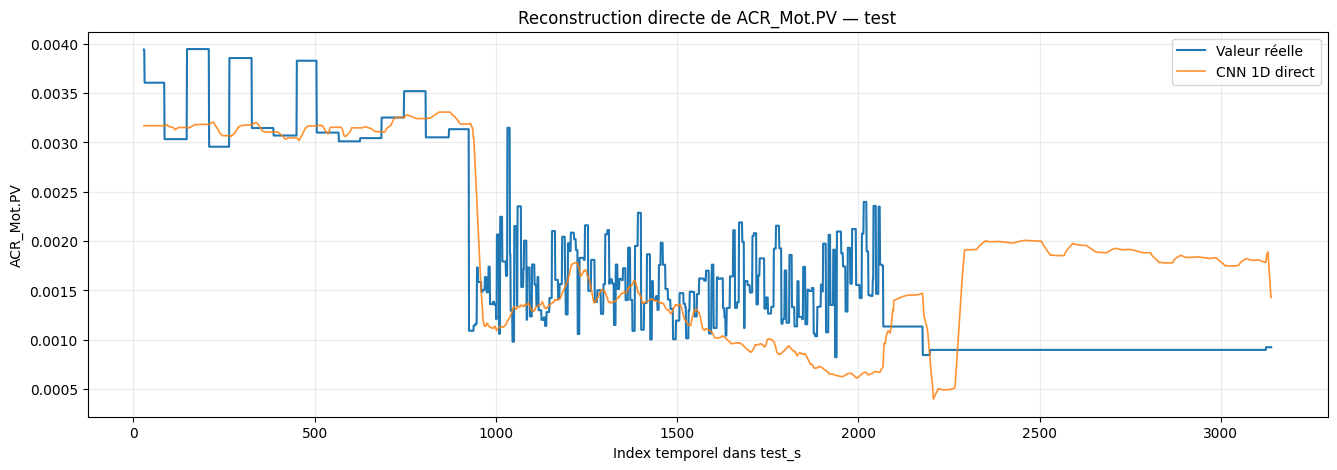

In [15]:
# ============================================================
# CNN 1D -> prédiction directe du capteur cible
# Sans lags explicites, SSI, SINDy ou XGBoost
#
# Prérequis :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# ------------------------------------------------------------
# 0. Paramètres
# ------------------------------------------------------------
SEED = 42

WINDOW = 30
CNN_EPOCHS = 150
CNN_BATCH_SIZE = 64
LEARNING_RATE = 1e-3

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ------------------------------------------------------------
# 1. Vérifications
# ------------------------------------------------------------
required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être dans OBS_SSI_SENSORS."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes."
    )

# ------------------------------------------------------------
# 2. Données
# ------------------------------------------------------------
X_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
X_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)

# ------------------------------------------------------------
# 3. Fenêtres temporelles strictement alignées
#
# Pour prédire y[t], le CNN reçoit :
# X[t-WINDOW+1], ..., X[t]
# ------------------------------------------------------------
def create_cnn_windows(
    observed_sensors,
    target,
    window,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    if len(observed_sensors) != len(target):
        raise ValueError(
            "observed_sensors et target doivent avoir la même longueur."
        )

    if len(target) < window:
        raise ValueError(
            f"Pas assez de lignes pour WINDOW={window}."
        )

    valid_t = np.arange(
        window - 1,
        len(target),
    )

    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    y = target[valid_t]

    return X_cnn, y, valid_t


X_cnn_train, y_train, idx_train = create_cnn_windows(
    X_train_obs,
    y_train_full,
    WINDOW,
)

X_cnn_val, y_val, idx_val = create_cnn_windows(
    X_val_obs,
    y_val_full,
    WINDOW,
)

X_cnn_test, y_test, idx_test = create_cnn_windows(
    X_test_obs,
    y_test_full,
    WINDOW,
)

print("=" * 65)
print("DIMENSIONS")
print("=" * 65)
print("Train      :", X_cnn_train.shape, y_train.shape)
print("Validation :", X_cnn_val.shape, y_val.shape)
print("Test       :", X_cnn_test.shape, y_test.shape)

# ------------------------------------------------------------
# 4. CNN 1D direct
#
# GlobalAveragePooling conserve une architecture compacte,
# pour limiter le surapprentissage.
# ------------------------------------------------------------
n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(
        WINDOW,
        n_observed_sensors,
    ),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.GlobalAveragePooling1D()(x)

x = tf.keras.layers.Dense(
    32,
    activation="relu",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="target_prediction",
)(x)

cnn_direct_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="cnn_1d_direct_regression",
)

cnn_direct_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_direct_model.summary()

# ------------------------------------------------------------
# 5. Entraînement
# ------------------------------------------------------------
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-5,
        verbose=1,
    ),
]

history_cnn_direct = cnn_direct_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)

# ------------------------------------------------------------
# 6. Prédictions
# ------------------------------------------------------------
y_train_pred = cnn_direct_model.predict(
    X_cnn_train,
    verbose=0,
).ravel()

y_val_pred = cnn_direct_model.predict(
    X_cnn_val,
    verbose=0,
).ravel()

y_test_pred = cnn_direct_model.predict(
    X_cnn_test,
    verbose=0,
).ravel()

# ------------------------------------------------------------
# 7. Métriques
# ------------------------------------------------------------
def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": np.corrcoef(
            y_true,
            y_pred,
        )[0, 1],
    }

metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques — espace standardisé :")
display(metrics_scaled)

# ------------------------------------------------------------
# 8. Retour à l'unité originale du capteur cible seulement
# ------------------------------------------------------------
TARGET_IDX = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[TARGET_IDX]
)

TARGET_SCALE = float(
    scaler.scale_[TARGET_IDX]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )

y_train_original = inverse_target_scale(y_train)
y_val_original = inverse_target_scale(y_val)
y_test_original = inverse_target_scale(y_test)

y_train_pred_original = inverse_target_scale(y_train_pred)
y_val_pred_original = inverse_target_scale(y_val_pred)
y_test_pred_original = inverse_target_scale(y_test_pred)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print("\nMétriques — unité originale :")
display(metrics_original)

# ------------------------------------------------------------
# 9. Courbe de perte
# ------------------------------------------------------------
plt.figure(figsize=(10, 4))

plt.plot(
    history_cnn_direct.history["loss"],
    label="Train loss",
)

plt.plot(
    history_cnn_direct.history["val_loss"],
    label="Validation loss",
)

plt.title("Apprentissage du CNN direct")
plt.xlabel("Époque")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# ------------------------------------------------------------
# 10. Résultats test et graphe
# ------------------------------------------------------------
results_test_cnn_direct = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

display(results_test_cnn_direct.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test_cnn_direct["time_index_in_test"],
    results_test_cnn_direct["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test_cnn_direct["time_index_in_test"],
    results_test_cnn_direct["y_pred_original"],
    label="CNN 1D direct",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction directe de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Test : R² = 0,505, corrélation = 0,730** (RMSE unité originale = 0,000708) -- nettement moins bon que toute variante combinée avec XGBoost.

### Variante 5 -- SSI + SINDy + retards → XGBoost, alignement temporel strict

SINDy — APPRENTISSAGE SUR LES ÉTATS SSI OBSERVÉS
⚠️ SINDy : 223 états hors domaine. Max = 8.9025
⚠️ SINDy : 1239 états hors domaine. Max = 11.4278
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.9311
⚠️ SINDy : 223 états hors domaine. Max = 8.9025
⚠️ SINDy : 1239 états hors domaine. Max = 11.4278
⚠️ Dérivée SINDy élevée : max |dx/dt| = 14.9311


... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (34 lignes omises) ...

XGBoost + SSI + SINDy — Validation
RMSE        = 0.330192
MAE         = 0.256864
R²          = 0.904933
Corrélation = 0.981019

XGBoost + SSI + SINDy — Test
RMSE        = 0.620085
MAE         = 0.497312
R²          = 0.689307
Corrélation = 0.863959


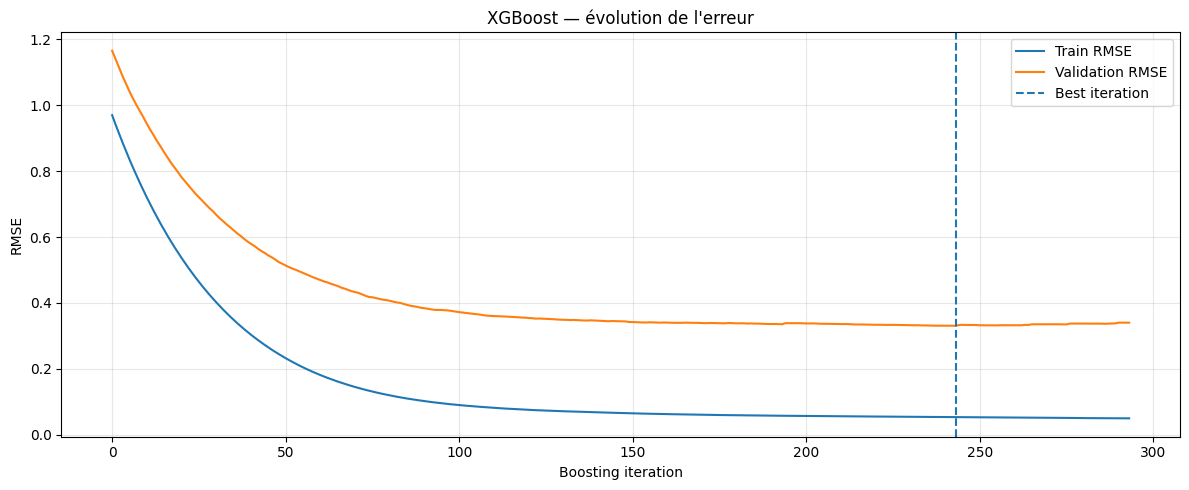

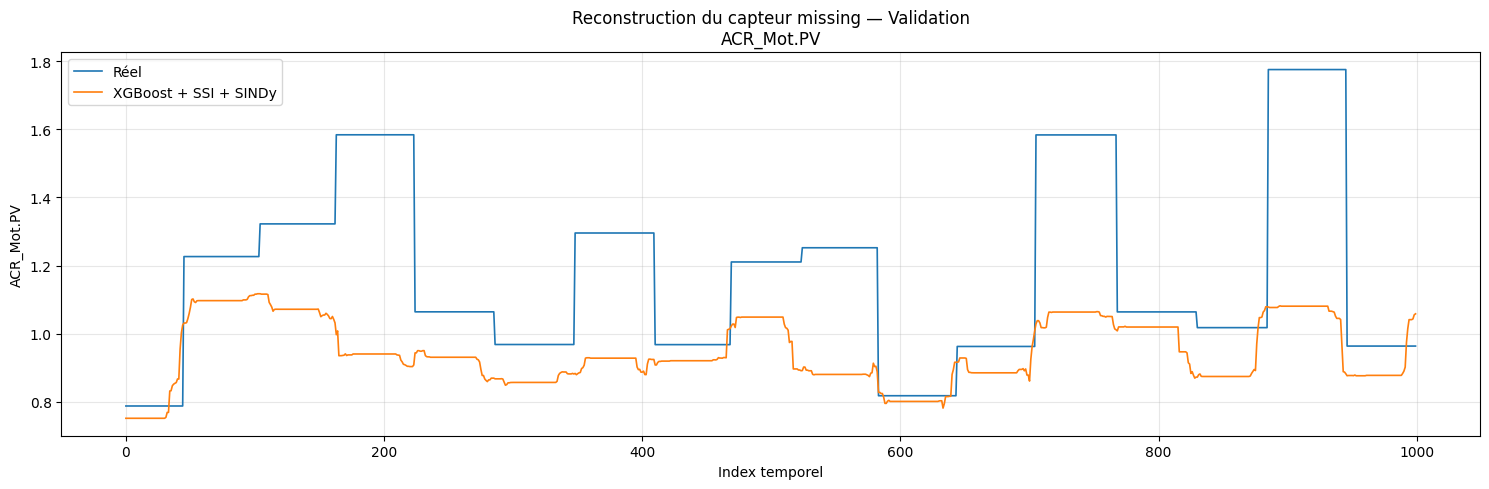

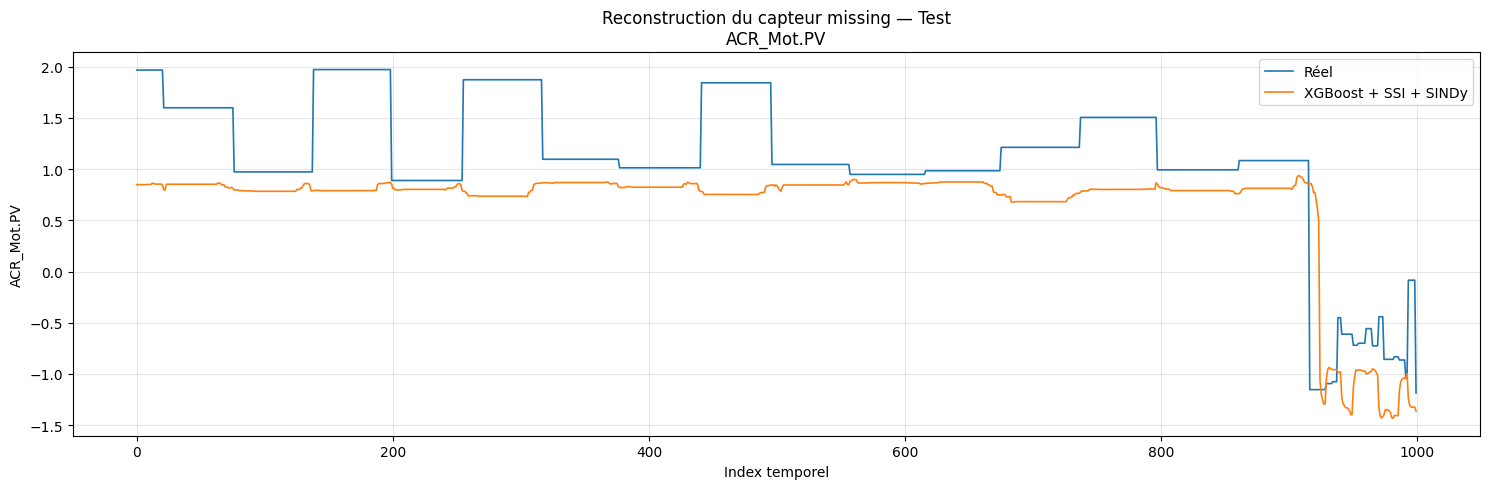

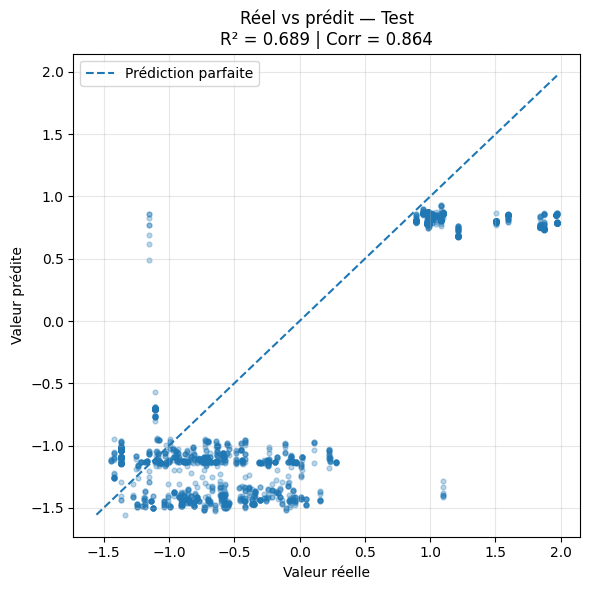

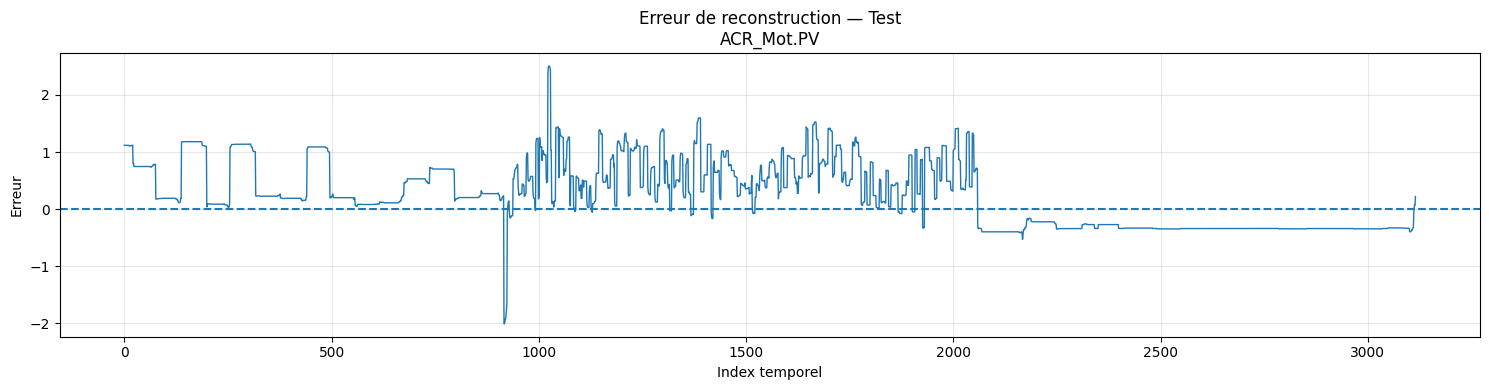

In [16]:
# ============================================================
# SSI → SINDy → LAGS → XGBoost
# VERSION ROBUSTE AVEC ALIGNEMENT STRICT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ============================================================
# 1. SINDy
# ============================================================
SINDY_POLY_DEGREES = [2, 3]

# Degré par défaut
SINDY_POLY_DEGREE = 3

# Régularisation Ridge
SINDY_ALPHA = 0.05

# Thresholds testés
SINDY_THRESHOLD_CANDIDATES = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2
]

# Fonctions trigonométriques
SINDY_INCLUDE_TRIG = False


# ============================================================
# 2. PARAMÈTRES DE STABILITÉ
# ============================================================

# Limite des états normalisés
SINDY_STATE_LIMIT = 5.0

# Nombre de points utilisés pour le test
# de simulation libre courte
SINDY_STABILITY_STEPS = 300


print("=" * 70)
print("SINDy — APPRENTISSAGE SUR LES ÉTATS SSI OBSERVÉS")
print("=" * 70)

sindy_model.fit(
    X_train_hat_obs,
    t=np.arange(len(X_train_hat_obs)) * DT_APPROX
)


# ============================================================
# 2. DYNAMIQUE SINDy
# ============================================================

Xdot_train_sindy = sindy_model.predict(
    X_train_hat_sindy
)

Xdot_val_sindy = sindy_model.predict(
    X_val_hat_sindy
)

Xdot_test_sindy = sindy_model.predict(
    X_test_hat_sindy
)


# ============================================================
# 3. PRÉDICTION ONE-STEP SINDy
# ============================================================

Xnext_train_sindy = sindy_model.predict_one_step(
    X_train_hat_sindy,
    DT_APPROX
)

Xnext_val_sindy = sindy_model.predict_one_step(
    X_val_hat_sindy,
    DT_APPROX
)

Xnext_test_sindy = sindy_model.predict_one_step(
    X_test_hat_sindy,
    DT_APPROX
)


# ============================================================
# 4. ALIGNEMENT STRICT SINDy
# ============================================================

n_train = min(
    len(X_train_hat_obs),
    len(Xdot_train_sindy),
    len(Xnext_train_sindy)
)

n_val = min(
    len(X_val_hat_obs),
    len(Xdot_val_sindy),
    len(Xnext_val_sindy)
)

n_test = min(
    len(X_test_hat_obs),
    len(Xdot_test_sindy),
    len(Xnext_test_sindy)
)


print("\nDimensions SINDy avant construction :")

print(
    f"Train : SSI={len(X_train_hat_obs)}, "
    f"Xdot={len(Xdot_train_sindy)}, "
    f"Xnext={len(Xnext_train_sindy)} "
    f"→ n_train={n_train}"
)

print(
    f"Val   : SSI={len(X_val_hat_obs)}, "
    f"Xdot={len(Xdot_val_sindy)}, "
    f"Xnext={len(Xnext_val_sindy)} "
    f"→ n_val={n_val}"
)

print(
    f"Test  : SSI={len(X_test_hat_obs)}, "
    f"Xdot={len(Xdot_test_sindy)}, "
    f"Xnext={len(Xnext_test_sindy)} "
    f"→ n_test={n_test}"
)


# ============================================================
# 5. FEATURES SSI + SINDy
# ============================================================

X_train_sindy_features = np.column_stack([
    X_train_hat_obs[:n_train],
    Xdot_train_sindy[:n_train],
    Xnext_train_sindy[:n_train]
])

X_val_sindy_features = np.column_stack([
    X_val_hat_obs[:n_val],
    Xdot_val_sindy[:n_val],
    Xnext_val_sindy[:n_val]
])

X_test_sindy_features = np.column_stack([
    X_test_hat_obs[:n_test],
    Xdot_test_sindy[:n_test],
    Xnext_test_sindy[:n_test]
])


print("\nDimensions SSI + SINDy :")

print(
    "Train :",
    X_train_sindy_features.shape
)

print(
    "Val   :",
    X_val_sindy_features.shape
)

print(
    "Test  :",
    X_test_sindy_features.shape
)


# ============================================================
# 6. LAGS
# ============================================================

N_LAGS = 10


def create_lag_features(
    df,
    sensor_columns,
    n_lags
):

    data = {}

    for sensor in sensor_columns:

        for lag in range(n_lags + 1):

            data[
                f"{sensor}_lag{lag}"
            ] = df[sensor].shift(lag)

    return pd.DataFrame(
        data,
        index=df.index
    )


X_train_lags = create_lag_features(
    train_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_val_lags = create_lag_features(
    val_s,
    OBS_SSI_SENSORS,
    N_LAGS
)

X_test_lags = create_lag_features(
    test_s,
    OBS_SSI_SENSORS,
    N_LAGS
)


# ============================================================
# 7. ALIGNEMENT LAGS + SINDy
# ============================================================

X_train_lags = (
    X_train_lags
    .iloc[:n_train]
    .reset_index(drop=True)
)

X_val_lags = (
    X_val_lags
    .iloc[:n_val]
    .reset_index(drop=True)
)

X_test_lags = (
    X_test_lags
    .iloc[:n_test]
    .reset_index(drop=True)
)


X_train_sindy_df = pd.DataFrame(
    X_train_sindy_features
).reset_index(drop=True)

X_val_sindy_df = pd.DataFrame(
    X_val_sindy_features
).reset_index(drop=True)

X_test_sindy_df = pd.DataFrame(
    X_test_sindy_features
).reset_index(drop=True)


# ============================================================
# 8. CONSTRUCTION FEATURES HYBRIDES
# ============================================================

X_train_hybrid = pd.concat(
    [
        X_train_lags,
        X_train_sindy_df
    ],
    axis=1
)

X_val_hybrid = pd.concat(
    [
        X_val_lags,
        X_val_sindy_df
    ],
    axis=1
)

X_test_hybrid = pd.concat(
    [
        X_test_lags,
        X_test_sindy_df
    ],
    axis=1
)


# ============================================================
# 9. TARGETS
# ============================================================
#
# TRÈS IMPORTANT :
# les targets sont tronquées avec EXACTEMENT le même n_train
# utilisé pour construire X.
#

y_train_full = (
    train_s[TARGET_SENSOR]
    .iloc[:n_train]
    .reset_index(drop=True)
)

y_val_full = (
    val_s[TARGET_SENSOR]
    .iloc[:n_val]
    .reset_index(drop=True)
)

y_test_full = (
    test_s[TARGET_SENSOR]
    .iloc[:n_test]
    .reset_index(drop=True)
)


# ============================================================
# 10. VÉRIFICATION AVANT MASQUE
# ============================================================

print("\n" + "=" * 70)
print("AVANT MASQUE")
print("=" * 70)

print(
    "Train X :",
    X_train_hybrid.shape,
    "| y :",
    y_train_full.shape
)

print(
    "Val X   :",
    X_val_hybrid.shape,
    "| y :",
    y_val_full.shape
)

print(
    "Test X  :",
    X_test_hybrid.shape,
    "| y :",
    y_test_full.shape
)


assert len(X_train_hybrid) == len(y_train_full)
assert len(X_val_hybrid) == len(y_val_full)
assert len(X_test_hybrid) == len(y_test_full)


# ============================================================
# 11. MASQUES
# ============================================================

train_mask = (
    X_train_hybrid.notna().all(axis=1)
    &
    y_train_full.notna()
)

val_mask = (
    X_val_hybrid.notna().all(axis=1)
    &
    y_val_full.notna()
)

test_mask = (
    X_test_hybrid.notna().all(axis=1)
    &
    y_test_full.notna()
)


# ============================================================
# 12. APPLICATION DES MASQUES
# ============================================================

X_train_hybrid = (
    X_train_hybrid
    .loc[train_mask]
    .reset_index(drop=True)
)

X_val_hybrid = (
    X_val_hybrid
    .loc[val_mask]
    .reset_index(drop=True)
)

X_test_hybrid = (
    X_test_hybrid
    .loc[test_mask]
    .reset_index(drop=True)
)


y_train = (
    y_train_full
    .loc[train_mask]
    .reset_index(drop=True)
)

y_val = (
    y_val_full
    .loc[val_mask]
    .reset_index(drop=True)
)

y_test = (
    y_test_full
    .loc[test_mask]
    .reset_index(drop=True)
)


# ============================================================
# 13. VÉRIFICATION FINALE
# ============================================================

print("\n" + "=" * 70)
print("ALIGNEMENT FINAL")
print("=" * 70)

print(
    "Train X :",
    X_train_hybrid.shape,
    "| Train y :",
    y_train.shape
)

print(
    "Val X   :",
    X_val_hybrid.shape,
    "| Val y   :",
    y_val.shape
)

print(
    "Test X  :",
    X_test_hybrid.shape,
    "| Test y :",
    y_test.shape
)


assert len(X_train_hybrid) == len(y_train)
assert len(X_val_hybrid) == len(y_val)
assert len(X_test_hybrid) == len(y_test)

assert np.isfinite(
    X_train_hybrid.values
).all()

assert np.isfinite(
    X_val_hybrid.values
).all()

assert np.isfinite(
    X_test_hybrid.values
).all()


print("\n✓ Alignement X/y correct.")
print("✓ Aucun NaN dans les features finales.")
print("✓ Aucun problème de dimension.")


# ============================================================
# 14. XGBOOST
# ============================================================

XGB_PARAMS = {

    # Maximum de 1000 arbres
    "n_estimators": 1000,

    # Arbres peu profonds pour limiter le sur-apprentissage
    "max_depth": 3,

    # Learning rate faible
    "learning_rate": 0.03,

    # Sous-échantillonnage
    "subsample": 0.8,
    "colsample_bytree": 0.8,

    # Régularisation
    "min_child_weight": 3,
    "reg_alpha": 0.01,
    "reg_lambda": 1.0,

    "objective": "reg:squarederror",
    "eval_metric": "rmse",

    "random_state": 42,
    "n_jobs": -1,

    # Early stopping
    "early_stopping_rounds": 50
}


xgb_hybrid = XGBRegressor(
    **XGB_PARAMS
)


# ============================================================
# 15. ENTRAÎNEMENT
# ============================================================

xgb_hybrid.fit(
    X_train_hybrid,
    y_train,

    eval_set=[
        (X_train_hybrid, y_train),
        (X_val_hybrid, y_val)
    ],

    verbose=False
)


print("\n" + "=" * 70)
print("XGBoost entraîné")
print("=" * 70)

print(
    "Nombre d'arbres utilisés :",
    xgb_hybrid.best_iteration + 1
)

print(
    "Meilleur RMSE validation :",
    xgb_hybrid.best_score
)


# ============================================================
# 16. PRÉDICTIONS
# ============================================================

y_val_pred = xgb_hybrid.predict(
    X_val_hybrid
)

y_test_pred = xgb_hybrid.predict(
    X_test_hybrid
)


# ============================================================
# 17. ÉVALUATION
# ============================================================

def evaluate(
    y_true,
    y_pred,
    name
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    corr = np.corrcoef(
        y_true,
        y_pred
    )[0, 1]

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        f"RMSE        = {rmse:.6f}"
    )

    print(
        f"MAE         = {mae:.6f}"
    )

    print(
        f"R²          = {r2:.6f}"
    )

    print(
        f"Corrélation = {corr:.6f}"
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Correlation": corr
    }


results_val = evaluate(
    y_val,
    y_val_pred,
    "XGBoost + SSI + SINDy — Validation"
)


results_test = evaluate(
    y_test,
    y_test_pred,
    "XGBoost + SSI + SINDy — Test"
)


# ============================================================
# 18. COURBE D'APPRENTISSAGE XGBOOST
# ============================================================

evals_result = xgb_hybrid.evals_result()

train_rmse = evals_result["validation_0"]["rmse"]
val_rmse = evals_result["validation_1"]["rmse"]

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    train_rmse,
    label="Train RMSE"
)

plt.plot(
    val_rmse,
    label="Validation RMSE"
)

plt.axvline(
    x=xgb_hybrid.best_iteration,
    linestyle="--",
    label="Best iteration"
)

plt.xlabel("Boosting iteration")
plt.ylabel("RMSE")

plt.title(
    "XGBoost — évolution de l'erreur"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 19. PLOT VALIDATION
# ============================================================

n_plot = min(
    1000,
    len(y_val)
)

plt.figure(
    figsize=(15, 5)
)

plt.plot(
    y_val.iloc[:n_plot].values,
    label="Réel",
    lw=1.2
)

plt.plot(
    y_val_pred[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1.2
)

plt.title(
    f"Reconstruction du capteur missing — Validation\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 20. PLOT TEST
# ============================================================

n_plot = min(
    1000,
    len(y_test)
)

plt.figure(
    figsize=(15, 5)
)

plt.plot(
    y_test.iloc[:n_plot].values,
    label="Réel",
    lw=1.2
)

plt.plot(
    y_test_pred[:n_plot],
    label="XGBoost + SSI + SINDy",
    lw=1.2
)

plt.title(
    f"Reconstruction du capteur missing — Test\n"
    f"{TARGET_SENSOR}"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    TARGET_SENSOR
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 21. SCATTER RÉEL VS PRÉDIT
# ============================================================

plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.3,
    s=12
)

lims = [
    min(y_test.min(), y_test_pred.min()),
    max(y_test.max(), y_test_pred.max())
]

plt.plot(
    lims,
    lims,
    linestyle="--",
    label="Prédiction parfaite"
)

plt.xlabel(
    "Valeur réelle"
)

plt.ylabel(
    "Valeur prédite"
)

plt.title(
    f"Réel vs prédit — Test\n"
    f"R² = {results_test['R2']:.3f} | "
    f"Corr = {results_test['Correlation']:.3f}"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 22. ERREUR DE RECONSTRUCTION
# ============================================================

test_error = (
    y_test.values -
    y_test_pred
)

plt.figure(
    figsize=(15, 4)
)

plt.plot(
    test_error,
    lw=1
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Index temporel"
)

plt.ylabel(
    "Erreur"
)

plt.title(
    f"Erreur de reconstruction — Test\n"
    f"{TARGET_SENSOR}"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Test : R² = 0,689, corrélation = 0,864** (RMSE unité originale = 0,000454).

### Variante 6 -- CNN 1D + SSI + SINDy + retards → XGBoost (tout combiné)

ALIGNEMENT SSI
Train        | observations =   9410 | états SSI =   9396 | décalage = 14
Validation   | observations =   3136 | états SSI =   3122 | décalage = 14
Test         | observations =   3140 | états SSI =   3126 | décalage = 14

Décalage SSI retenu : 14
⚠️ SINDy : 54 états hors domaine. Max = 9.4771
⚠️ SINDy : 1222 états hors domaine. Max = 11.4019

... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (38 lignes omises) ...

Epoch 14/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0061 - mae: 0.0498 - val_loss: 0.2245 - val_mae: 0.3730
Epoch 15/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0062 - mae: 0.0516 - val_loss: 0.2364 - val_mae: 0.3882
Epoch 16/100
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0063 - mae: 0.0527 - val_loss: 0.2785 - val_mae: 0.4252

DIMENSIONS FINALES XGBOOST
Train      : (9381, 147)
Validation : (3107, 147)
Test       : (3111, 147)

Métriques dans l'espace standardisé :


,split,RMSE,MAE,R2,Correlation
0,Train,0.061023,0.037859,0.996278,0.998196
1,Validation,0.581656,0.478039,0.709279,0.931069
2,Test,0.834794,0.710249,0.425380,0.746943



Capteur cible : ACR_Mot.PV
TARGET_MEAN  : 0.00214400
TARGET_SCALE : 0.00091395

Métriques dans l'unité originale du capteur :


,split,RMSE,MAE,R2,Correlation
0,Train,0.000056,0.000035,0.996278,0.998196
1,Validation,0.000532,0.000437,0.709279,0.931069
2,Test,0.000763,0.000649,0.425381,0.746943



Aperçu des résultats test :


,time_index_in_test,y_true_scaled,y_pred_scaled,y_true_original,y_pred_original
0,29,1.965860,0.794586,0.003941,0.002870
1,30,1.965860,0.794586,0.003941,0.002870
2,31,1.597892,0.794586,0.003604,0.002870
3,32,1.597892,0.794586,0.003604,0.002870
4,33,1.597892,0.786389,0.003604,0.002863


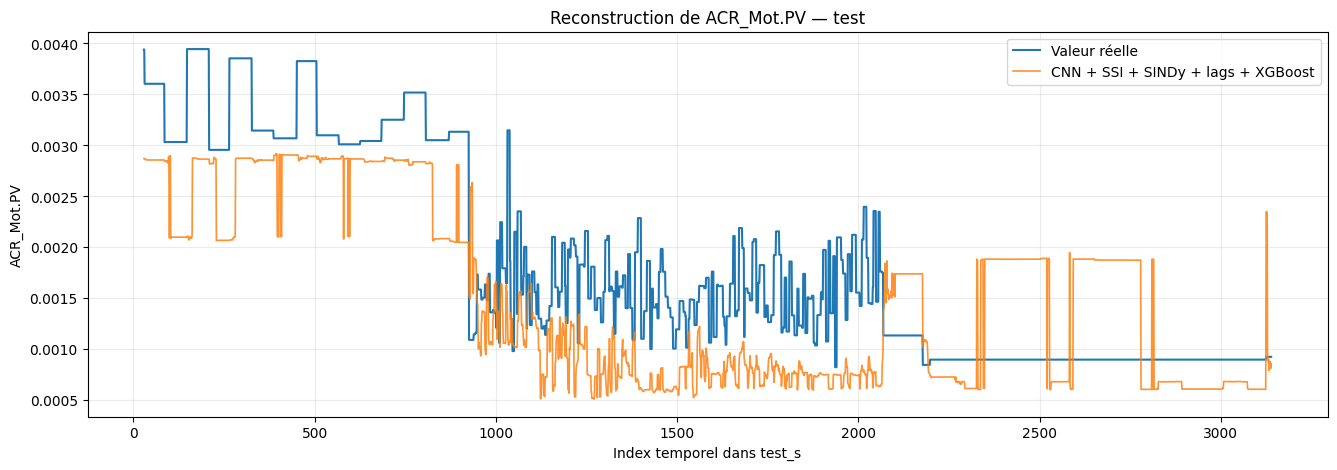

In [17]:
# ============================================================
# CNN 1D + SSI + SINDy + Lags -> XGBoost
# Reconstruction de TARGET_SENSOR sans l'utiliser en entrée
#
# Prérequis déjà définis dans le notebook :
# train_s, val_s, test_s, scaler
# TARGET_SENSOR, OBS_SSI_SENSORS
# SSI_BLOCK_ROWS, SSI_ORDER
# ssi_cov(), ssi_estimate_states()
# sindy_model
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor


# ============================================================
# 0. PARAMÈTRES
# ============================================================

SEED = 42

WINDOW = 30
N_LAGS = 10

CNN_EPOCHS = 100
CNN_BATCH_SIZE = 64
CNN_EMBEDDING_DIM = 32

# Si DT_APPROX existe déjà dans le notebook, SINDy l'utilise.
# Sinon, on considère dt = 1.
DT_SINDY = float(globals().get("DT_APPROX", 1.0))

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ============================================================
# 1. VÉRIFICATIONS
# ============================================================

required_variables = [
    "train_s",
    "val_s",
    "test_s",
    "scaler",
    "TARGET_SENSOR",
    "OBS_SSI_SENSORS",
    "SSI_BLOCK_ROWS",
    "SSI_ORDER",
    "ssi_cov",
    "ssi_estimate_states",
    "sindy_model",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Variables/fonctions manquantes : "
        + ", ".join(missing_variables)
    )

if TARGET_SENSOR in OBS_SSI_SENSORS:
    raise ValueError(
        f"{TARGET_SENSOR} ne doit pas être inclus dans OBS_SSI_SENSORS."
    )

if TARGET_SENSOR not in train_s.columns:
    raise ValueError(
        f"Le capteur cible {TARGET_SENSOR} est absent de train_s."
    )

if (
    list(train_s.columns) != list(val_s.columns)
    or list(train_s.columns) != list(test_s.columns)
):
    raise ValueError(
        "train_s, val_s et test_s doivent avoir les mêmes colonnes "
        "dans le même ordre."
    )


# ============================================================
# 2. DONNÉES OBSERVÉES ET CIBLE
# ============================================================

# Les entrées ne contiennent jamais TARGET_SENSOR.
Y_train_obs = train_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_val_obs = val_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)
Y_test_obs = test_s[OBS_SSI_SENSORS].to_numpy(dtype=np.float32)

# Cible standardisée : elle est utilisée seulement comme y.
y_train_full = train_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_val_full = val_s[TARGET_SENSOR].to_numpy(dtype=np.float32)
y_test_full = test_s[TARGET_SENSOR].to_numpy(dtype=np.float32)


# ============================================================
# 3. SSI : IDENTIFICATION SUR TRAIN UNIQUEMENT
# ============================================================

A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER,
)

X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS,
)

X_train_hat_obs = np.asarray(
    X_train_hat_obs,
    dtype=np.float32,
)

X_val_hat_obs = np.asarray(
    X_val_hat_obs,
    dtype=np.float32,
)

X_test_hat_obs = np.asarray(
    X_test_hat_obs,
    dtype=np.float32,
)


# ============================================================
# 4. DÉCALAGE TEMPOREL SSI
#
# Exemple :
# 9410 observations brutes
# 9396 états SSI
# offset = 14
#
# Alors :
# état SSI[k] <-> instant brut t = k + 14
# ============================================================

def get_ssi_offset(
    states,
    observations,
    split_name,
):
    offset = len(observations) - len(states)

    if offset < 0:
        raise ValueError(
            f"SSI renvoie trop d'états sur {split_name} : "
            f"{len(states)} états pour {len(observations)} observations."
        )

    print(
        f"{split_name:<12} | "
        f"observations = {len(observations):>6} | "
        f"états SSI = {len(states):>6} | "
        f"décalage = {offset}"
    )

    return offset


print("=" * 70)
print("ALIGNEMENT SSI")
print("=" * 70)

SSI_OFFSET_TRAIN = get_ssi_offset(
    X_train_hat_obs,
    Y_train_obs,
    "Train",
)

SSI_OFFSET_VAL = get_ssi_offset(
    X_val_hat_obs,
    Y_val_obs,
    "Validation",
)

SSI_OFFSET_TEST = get_ssi_offset(
    X_test_hat_obs,
    Y_test_obs,
    "Test",
)

if not (
    SSI_OFFSET_TRAIN
    == SSI_OFFSET_VAL
    == SSI_OFFSET_TEST
):
    raise ValueError(
        "Le décalage SSI doit être identique sur train, validation et test."
    )

SSI_OFFSET = SSI_OFFSET_TRAIN

print("\nDécalage SSI retenu :", SSI_OFFSET)


# ============================================================
# 5. SINDy
# ============================================================

# Standardisation des états SSI apprise uniquement sur train.
SINDY_SCALER = StandardScaler()

X_train_hat_sindy = SINDY_SCALER.fit_transform(
    X_train_hat_obs
)

X_val_hat_sindy = SINDY_SCALER.transform(
    X_val_hat_obs
)

X_test_hat_sindy = SINDY_SCALER.transform(
    X_test_hat_obs
)

# SINDy est entraîné uniquement sur les états SSI issus de train.
t_train_sindy = (
    np.arange(len(X_train_hat_sindy), dtype=float)
    * DT_SINDY
)

sindy_model.fit(
    X_train_hat_sindy,
    t=t_train_sindy,
)

# Features dynamiques SINDy : dérivées prédites dX/dt.
Xdot_train_sindy = sindy_model.predict(
    X_train_hat_sindy
)

Xdot_val_sindy = sindy_model.predict(
    X_val_hat_sindy
)

Xdot_test_sindy = sindy_model.predict(
    X_test_hat_sindy
)

Xdot_train_sindy = np.asarray(
    Xdot_train_sindy,
    dtype=np.float32,
)

Xdot_val_sindy = np.asarray(
    Xdot_val_sindy,
    dtype=np.float32,
)

Xdot_test_sindy = np.asarray(
    Xdot_test_sindy,
    dtype=np.float32,
)


# ============================================================
# 6. CONSTRUCTION DES ENTRÉES ALIGNÉES
#
# Pour chaque instant brut t :
#
# CNN   : observés[t-WINDOW+1 : t+1]
# Lags  : observés[t], ..., observés[t-N_LAGS]
# SSI   : états_SSI[t - SSI_OFFSET]
# SINDy : features_SINDy[t - SSI_OFFSET]
# y     : cible[t]
# ============================================================

def build_aligned_split(
    observed_sensors,
    ssi_states,
    sindy_features,
    target,
    window,
    n_lags,
    ssi_offset,
):
    observed_sensors = np.asarray(
        observed_sensors,
        dtype=np.float32,
    )

    ssi_states = np.asarray(
        ssi_states,
        dtype=np.float32,
    )

    '''sindy_features = np.asarray(
        sindy_features,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )'''

    n_raw = len(target)

    if len(observed_sensors) != n_raw:
        raise ValueError(
            "Les observations et la cible n'ont pas la même longueur."
        )

    if len(ssi_states) != len(sindy_features):
        raise ValueError(
            "Les états SSI et les features SINDy n'ont pas la même longueur."
        )

    if len(ssi_states) != n_raw - ssi_offset:
        raise ValueError(
            "Dimensions incompatibles entre les données brutes, "
            "les états SSI et SSI_OFFSET."
        )

    # Premier instant compatible avec :
    # - la fenêtre CNN ;
    # - les lags ;
    # - le premier état SSI disponible.
    first_t = max(
        window - 1,
        n_lags,
        ssi_offset,
    )

    if n_raw <= first_t:
        raise ValueError(
            f"Pas assez d'observations ({n_raw}) pour "
            f"WINDOW={window}, N_LAGS={n_lags} et "
            f"SSI_OFFSET={ssi_offset}."
        )

    # Instants dans les données brutes.
    valid_t = np.arange(
        first_t,
        n_raw,
    )

    # ----------------------------
    # Entrées CNN :
    # shape = (n_samples, WINDOW, n_sensors)
    # ----------------------------
    X_cnn = np.stack(
        [
            observed_sensors[
                t - window + 1:t + 1
            ]
            for t in valid_t
        ],
        axis=0,
    )

    # ----------------------------
    # Lags :
    # [x(t), x(t-1), ..., x(t-N_LAGS)]
    # ----------------------------
    X_lags = np.concatenate(
        [
            np.stack(
                [
                    observed_sensors[t - lag]
                    for t in valid_t
                ],
                axis=0,
            )
            for lag in range(n_lags + 1)
        ],
        axis=1,
    )

    # ----------------------------
    # Conversion temps brut -> index SSI/SINDy
    # ----------------------------
    ssi_indices = valid_t - ssi_offset

    X_ssi = ssi_states[ssi_indices]
    X_sindy = sindy_features[ssi_indices]

    # Cible au même instant t.
    y = target[valid_t]

    return (
        X_cnn,
        X_lags,
        X_ssi,
        X_sindy,
        y,
        valid_t,
    )


(
    X_cnn_train,
    X_lags_train,
    X_ssi_train,
    X_sindy_train,
    y_train,
    idx_train,
) = build_aligned_split(
    Y_train_obs,
    X_train_hat_obs,
    Xdot_train_sindy,
    y_train_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_val,
    X_lags_val,
    X_ssi_val,
    X_sindy_val,
    y_val,
    idx_val,
) = build_aligned_split(
    Y_val_obs,
    X_val_hat_obs,
    Xdot_val_sindy,
    y_val_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

(
    X_cnn_test,
    X_lags_test,
    X_ssi_test,
    X_sindy_test,
    y_test,
    idx_test,
) = build_aligned_split(
    Y_test_obs,
    X_test_hat_obs,
    Xdot_test_sindy,
    y_test_full,
    WINDOW,
    N_LAGS,
    SSI_OFFSET,
)

print("\n" + "=" * 70)
print("DIMENSIONS APRÈS ALIGNEMENT")
print("=" * 70)
print("CNN train   :", X_cnn_train.shape)
print("Lags train  :", X_lags_train.shape)
print("SSI train   :", X_ssi_train.shape)
print("SINDy train :", X_sindy_train.shape)
print("y train     :", y_train.shape)
print("CNN val     :", X_cnn_val.shape)
print("CNN test    :", X_cnn_test.shape)


# ============================================================
# 7. CNN 1D LÉGER
# ============================================================

n_observed_sensors = X_cnn_train.shape[-1]

cnn_input = tf.keras.Input(
    shape=(WINDOW, n_observed_sensors),
    name="observed_sensor_window",
)

x = tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=3,
    padding="causal",
    activation="relu",
)(cnn_input)

x = tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=5,
    padding="causal",
    activation="relu",
)(x)

# Préserve l'information temporelle au lieu de moyenner la fenêtre.
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
)(x)

x = tf.keras.layers.Dense(
    CNN_EMBEDDING_DIM,
    activation="relu",
    name="cnn_embedding",
)(x)

cnn_output = tf.keras.layers.Dense(
    1,
    name="cnn_target_prediction",
)(x)

cnn_model = tf.keras.Model(
    inputs=cnn_input,
    outputs=cnn_output,
    name="lightweight_cnn_1d",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mse",
    metrics=["mae"],
)

cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    )
]

history_cnn = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(
        X_cnn_val,
        y_val,
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    verbose=1,
    callbacks=cnn_callbacks,
    shuffle=True,
)


# ============================================================
# 8. EXTRACTION DES EMBEDDINGS CNN
# ============================================================

cnn_embedding_model = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "cnn_embedding"
    ).output,
    name="cnn_embedding_extractor",
)

X_cnn_emb_train = cnn_embedding_model.predict(
    X_cnn_train,
    verbose=0,
)

X_cnn_emb_val = cnn_embedding_model.predict(
    X_cnn_val,
    verbose=0,
)

X_cnn_emb_test = cnn_embedding_model.predict(
    X_cnn_test,
    verbose=0,
)


# ============================================================
# 9. FUSION CNN + SSI + SINDy + LAGS
# ============================================================

X_train_final = np.hstack([
    X_cnn_emb_train,
    X_ssi_train,
    X_sindy_train,
    X_lags_train,
]).astype(np.float32)

X_val_final = np.hstack([
    X_cnn_emb_val,
    X_ssi_val,
    X_sindy_val,
    X_lags_val,
]).astype(np.float32)

X_test_final = np.hstack([
    X_cnn_emb_test,
    X_ssi_test,
    X_sindy_test,
    X_lags_test,
]).astype(np.float32)

print("\n" + "=" * 70)
print("DIMENSIONS FINALES XGBOOST")
print("=" * 70)
print("Train      :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)


# ============================================================
# 10. XGBOOST
# ============================================================

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.80,
    colsample_bytree=0.80,
    reg_alpha=0.01,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    early_stopping_rounds=50,
)

xgb_model.fit(
    X_train_final,
    y_train,
    eval_set=[
        (
            X_val_final,
            y_val,
        )
    ],
    verbose=False,
)

# On ne remplace jamais y_test par les prédictions.
y_train_pred = xgb_model.predict(
    X_train_final
)

y_val_pred = xgb_model.predict(
    X_val_final
)

y_test_pred = xgb_model.predict(
    X_test_final
)


# ============================================================
# 11. MÉTRIQUES
# ============================================================

def regression_metrics(
    y_true,
    y_pred,
    split_name,
):
    correlation = np.corrcoef(
        y_true,
        y_pred,
    )[0, 1]

    return {
        "split": split_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true,
            y_pred,
        ),
        "R2": r2_score(
            y_true,
            y_pred,
        ),
        "Correlation": correlation,
    }


metrics_scaled = pd.DataFrame([
    regression_metrics(
        y_train,
        y_train_pred,
        "Train",
    ),
    regression_metrics(
        y_val,
        y_val_pred,
        "Validation",
    ),
    regression_metrics(
        y_test,
        y_test_pred,
        "Test",
    ),
])

print("\nMétriques dans l'espace standardisé :")
display(metrics_scaled)


# ============================================================
# 12. RETOUR À L'UNITÉ ORIGINALE DU CAPTEUR CIBLE
#
# Le scaler contient les paramètres des 10 capteurs.
# Il ne faut donc PAS appeler :
# scaler.inverse_transform(y.reshape(-1, 1))
# ============================================================

target_index = list(
    train_s.columns
).index(TARGET_SENSOR)

TARGET_MEAN = float(
    scaler.mean_[target_index]
)

TARGET_SCALE = float(
    scaler.scale_[target_index]
)

def inverse_target_scale(y_scaled):
    y_scaled = np.asarray(
        y_scaled,
        dtype=float,
    )

    return (
        y_scaled * TARGET_SCALE
        + TARGET_MEAN
    )


y_train_original = inverse_target_scale(
    y_train
)

y_val_original = inverse_target_scale(
    y_val
)

y_test_original = inverse_target_scale(
    y_test
)

y_train_pred_original = inverse_target_scale(
    y_train_pred
)

y_val_pred_original = inverse_target_scale(
    y_val_pred
)

y_test_pred_original = inverse_target_scale(
    y_test_pred
)

metrics_original = pd.DataFrame([
    regression_metrics(
        y_train_original,
        y_train_pred_original,
        "Train",
    ),
    regression_metrics(
        y_val_original,
        y_val_pred_original,
        "Validation",
    ),
    regression_metrics(
        y_test_original,
        y_test_pred_original,
        "Test",
    ),
])

print(f"\nCapteur cible : {TARGET_SENSOR}")
print(f"TARGET_MEAN  : {TARGET_MEAN:.8f}")
print(f"TARGET_SCALE : {TARGET_SCALE:.8f}")

print("\nMétriques dans l'unité originale du capteur :")
display(metrics_original)


# ============================================================
# 13. RÉSULTATS TEST ET VISUALISATION
# ============================================================

results_test = pd.DataFrame({
    "time_index_in_test": idx_test,
    "y_true_scaled": y_test,
    "y_pred_scaled": y_test_pred,
    "y_true_original": y_test_original,
    "y_pred_original": y_test_pred_original,
})

print("\nAperçu des résultats test :")
display(results_test.head())

plt.figure(figsize=(16, 5))

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_true_original"],
    label="Valeur réelle",
    linewidth=1.5,
)

plt.plot(
    results_test["time_index_in_test"],
    results_test["y_pred_original"],
    label="CNN + SSI + SINDy + lags + XGBoost",
    linewidth=1.2,
    alpha=0.85,
)

plt.title(
    f"Reconstruction de {TARGET_SENSOR} — test"
)

plt.xlabel("Index temporel dans test_s")
plt.ylabel(TARGET_SENSOR)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Test : R² = 0,425, corrélation = 0,747** (RMSE unité originale = 0,000763), pour un **Train
R² = 0,996** -- l'écart Train/Test le plus marqué des six variantes, malgré (ou à cause de) la
combinaison de toutes les représentations disponibles (147 variables).

## Résultats -- synthèse

| Variante | Représentation d'entrée | R² Test | Corrélation Test | R² Train |
|---|---|---|---|---|
| 1 | SSI + SINDy + retards | 0,629 | 0,895 | -- |
| **2** | **CNN + SSI + retards** | **0,796** | **0,928** | 0,995 |
| 3 | CNN + retards (sans SSI) | 0,803 | 0,928 | 0,995 |
| 4 | CNN seul (sans XGBoost) | 0,505 | 0,730 | 0,967 |
| 5 | SSI + SINDy + retards (réaligné) | 0,689 | 0,864 | -- |
| 6 | CNN + SSI + SINDy + retards (tout) | 0,425 | 0,747 | **0,996** |

*(Toutes les métriques sont calculées sur l'ensemble du Test au sens standard -- prédiction
instant par instant sur toute la période, et non sur un scénario de panne continue simulé. Cette
distinction est cruciale et fait l'objet du notebook 7.)*

## Interprétation

Trois enseignements se dégagent, à lire avec prudence compte tenu de la mise en garde
méthodologique ci-dessous :

1. **XGBoost, quelle que soit la représentation fournie, obtient des scores nettement supérieurs à
   ceux du pipeline SSI+SINDy+Kalman du notebook 5** sur ce mode d'évaluation (R² de 0,42 à 0,80
   contre un R² négatif partout au notebook 5). Un modèle non contraint par une forme dynamique
   explicite semble mieux exploiter l'information disponible dans ce cadre d'évaluation.
2. **SSI n'apporte pas de gain visible une fois combiné à un CNN** (variante 2 vs variante 3 :
   0,796 vs 0,803, essentiellement équivalent) -- ce qui, avec le notebook 4, questionne l'utilité
   réelle de la brique SSI+SINDy dans une chaîne purement prédictive, une fois que le modèle a
   accès aux retards temporels bruts et à des motifs locaux appris directement par un CNN.
3. **Le CNN seul, sans XGBoost, est nettement moins bon** (R² = 0,505) que toutes les combinaisons
   avec XGBoost -- cohérent avec un jeu de données de taille modeste (environ 9 400 exemples
   d'entraînement) : le gradient boosting sur des features engineered semble mieux généraliser ici
   qu'un réseau de neurones appris de bout en bout.
4. **La variante la plus riche (6) est la moins bonne sur Test** malgré le meilleur score sur
   Train (0,996) -- une signature classique de surapprentissage : ajouter toutes les
   représentations disponibles (147 variables) ne se traduit pas par une meilleure généralisation.

## Limites -- une mise en garde essentielle avant le notebook 7

**Les scores ci-dessus sont calculés sur l'ensemble du Test, instant par instant** : à chaque pas
de temps évalué, le modèle dispose des retards récents des *autres* capteurs, réellement observés
à ce moment-là. Ce mode d'évaluation ne simule pas explicitement une panne prolongée et continue du
capteur cible sur une fenêtre dédiée -- contrairement aux tests 2, 3 et 4 du notebook 5, qui
évaluaient spécifiquement des fenêtres continues, des régions de pics et des fenêtres longues. Rien
dans ce notebook ne garantit donc que ces bons scores se maintiennent sur le scénario industriel
réellement critique (panne prolongée, éventuellement pendant un régime transitoire). C'est
exactement cette question que le notebook 7 tranche -- et la réponse y est très different de ce que
ce notebook pourrait laisser penser.

## Conclusion

## Transition vers l'approche suivante

Ce que ce notebook a permis de comprendre : XGBoost, sur une évaluation instant par instant sur
l'ensemble du Test, obtient des scores nettement meilleurs que le pipeline dynamique du notebook
5, et SSI n'y apporte pas de gain net une fois combiné à des retards bruts et à un CNN. Ce qu'il
n'a pas établi : que ces bons scores se maintiennent sur un véritable scénario de panne continue --
c'est une question distincte, que ce mode d'évaluation ne teste pas directement. Le notebook 7
reprend exactement la même famille de modèles (XGBoost) mais l'évalue cette fois sur des scénarios
de panne explicitement construits (fenêtre continue, région de pics, points aléatoires isolés),
avec des métriques supplémentaires (ratio d'amplitude, ratio d'écart-type) conçues précisément pour
détecter un échec de reconstruction de l'amplitude qu'un R² global pourrait masquer.